# SentinelX AI — Baseline RUL sur NASA C-MAPSS FD001

**Étape S3 · Premier modèle de prédiction du Remaining Useful Life (RUL)**

| Élément | Valeur |
|---|---|
| Projet | SentinelX AI — plateforme de maintenance prédictive & Maintenance Copilot RAG |
| Notebook | `02_baseline_fd001.ipynb` |
| Étape précédente | `01_eda_fd001_final_fusion.ipynb` (EDA terminée et validée) |
| Exigences couvertes | F-03 (feature pipeline), F-04 (baseline reproductible), F-06 (comparaison train / validation / test) · backlog B05, B06 |
| Definition of Done (README §10) | Baseline RUL entraîné, `baseline_metrics.json` et graphiques, **sans fuite d'information** |
| Étape suivante | S4 — modèle séquentiel LSTM / GRU, comparé à ce baseline sur le même split |

### Objectif de S3

Construire un **modèle de référence** (*baseline*) simple, rapide et interprétable qui prédit le RUL d'un moteur à partir de ses mesures au cycle courant.

Un baseline sert d'**étalon** : un modèle plus complexe (LSTM / GRU en S4) n'a d'intérêt que s'il fait **mesurablement mieux** que lui, sur le même protocole. Sans baseline, il est impossible de dire si un réseau de neurones apporte réellement quelque chose.

### Questions auxquelles ce notebook répond

| # | Question | Sections |
|---|---|---|
| Q1 | Quelle performance atteint un modèle linéaire sur les 17 variables candidates de l'EDA ? | 6, 7 |
| Q2 | Faut-il apprendre le RUL brut ou un RUL plafonné, et avec quel plafond ? | 8 |
| Q3 | La régularisation Ridge apporte-t-elle un gain, et pour quelle valeur d'`alpha` ? | 9 |
| Q4 | Linear Regression ou Ridge : lequel retenir, sur un critère objectif ? | 10 |
| Q5 | Les décisions « à valider » de l'EDA (ablations) changent-elles le résultat ? | 11 |
| Q6 | Où le modèle se trompe-t-il (par moteur, par tranche de RUL) ? | 13, 14 |
| Q7 | Quelle performance réelle sur le jeu de test officiel NASA ? | 16 |

### Règles anti-fuite appliquées (README §9)

1. **Split par moteur** : le split figé de l'EDA (`fd001_engine_split.json`) est réutilisé tel quel.
2. **`RUL_FD001.txt` est lu une seule fois**, en section 16, après que le pipeline a été **figé**. Il ne guide aucun choix.
3. **Aucune variable future** : `unit_id`, `RUL`, `max_cycle`, `life_pct`… sont interdits comme features (vérifié par `assert`).
4. **Preprocessing ajusté sur le train uniquement** : le `StandardScaler` est placé dans un `Pipeline`, réajusté à chaque fold.
5. **Validation croisée par groupes** (`GroupKFold`) : un moteur n'est jamais à la fois en apprentissage et en évaluation.
6. **Aucune métrique inventée** : chaque chiffre de la conclusion est revérifié par une cellule finale (section 19).

### Sommaire

0. Introduction
1. Configuration et reproductibilité
2. Chargement des données et des décisions de l'EDA
3. Construction de la cible RUL
4. Sélection des features
5. Préparation de X, y et des groupes
6. Outils : Pipeline, StandardScaler, métriques et validation croisée
7. Premiers modèles : Linear Regression et Ridge (RUL brut)
8. Cible : RUL brut ou RUL plafonné
9. Optimisation d'`alpha` pour Ridge
10. Comparaison objective des modèles
11. Ablations demandées par l'EDA
12. Gestion des prédictions RUL négatives
13. Vérification sur les 20 moteurs de validation figés
14. Graphiques : prédictions et erreurs
15. Entraînement final, sauvegarde et rechargement du modèle
16. Évaluation finale sur le test NASA FD001
17. Sauvegarde des métriques et artefacts
18. Conclusion
19. Vérification automatique des chiffres cités

## 1. Configuration et reproductibilité

**Objectif.** Déclarer en un seul endroit les bibliothèques, la graine aléatoire et **tous les paramètres d'expérience** (plafonds testés, grille d'`alpha`, nombre de folds…). Un lecteur doit pouvoir modifier une expérience sans chercher des constantes cachées dans le code.

Les valeurs testées sont des **choix d'expérience** déclarés à l'avance ; c'est la validation croisée qui décide ensuite.

In [1]:
from pathlib import Path
import hashlib
import json
import platform

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --- Paramètres de l'expérience ------------------------------------------------------
RANDOM_STATE = 42                     # même graine que l'EDA (utilisée pour les tirages illustratifs)
N_SPLITS = 5                          # nombre de folds de GroupKFold (80 moteurs -> 16 moteurs par fold)
RUL_CAPS = (None, 80, 90, 100, 110, 120, 125, 130, 140, 150)   # None = RUL brut, sinon RUL plafonné
RIDGE_ALPHAS = tuple(np.logspace(-3, 4, 15).round(6))          # grille d'alpha de 0,001 à 10 000
DEFAULT_RIDGE_ALPHA = 1.0             # alpha par défaut de scikit-learn, utilisé avant l'optimisation
ALPHA_TOLERANCE = 0.01                # cycles : écart de RMSE jugé négligeable pour départager les alpha
ROLLING_WINDOWS = (10, 30)            # fenêtres des moyennes glissantes causales testées en ablation (W <= 30)
RUL_BANDS = (0, 25, 75, 127, np.inf)  # tranches d'analyse d'erreur : proche panne / milieu / début de zone / début de vie
N_ENGINES_TO_PLOT = 4                 # moteurs de validation affichés en trajectoire

SAVE_FIGURES = True
SAVE_ARTIFACTS = True

# --- Affichage ----------------------------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})

# --- Traçabilité de l'environnement ---------------------------------------------------
VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__,
}
pd.Series(VERSIONS, name="version").to_frame()

,version
python,3.13.16
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
joblib,1.6.0


### 1.2 Localisation du projet

Comme dans l'EDA, le notebook cherche `data/raw/` dans le dossier courant puis dans le dossier parent : il fonctionne lancé depuis la racine du dépôt **ou** depuis `notebooks/`. Les sorties vont dans les dossiers prévus par le README §10.2 :

- `artifacts/baseline_fd001/` : métriques (`baseline_metrics.json`), modèle sérialisé, tableaux de résultats ;
- `reports/figures/baseline_fd001/` : graphiques.

In [2]:
REQUIRED_FILES = ("train_FD001.txt", "test_FD001.txt", "RUL_FD001.txt")

candidate_raw_dirs = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw",
    Path("/content/sentinelx-ai/data/raw"),  # exécution sous Google Colab
]
RAW_DIR = next((p for p in candidate_raw_dirs if all((p / f).exists() for f in REQUIRED_FILES)), None)
if RAW_DIR is None:
    raise FileNotFoundError(
        "Fichiers C-MAPSS FD001 introuvables. Copier train_FD001.txt, test_FD001.txt et "
        "RUL_FD001.txt dans data/raw/ (voir README §7) puis relancer le notebook."
    )

PROJECT_ROOT = RAW_DIR.parent.parent
TRAIN_PATH = RAW_DIR / "train_FD001.txt"
TEST_PATH = RAW_DIR / "test_FD001.txt"
RUL_TEST_PATH = RAW_DIR / "RUL_FD001.txt"   # vérité terrain du test : lue UNE fois, en section 16

EDA_ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "eda_fd001"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "baseline_fd001"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "baseline_fd001"
for directory in (ARTIFACT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", PROJECT_ROOT.resolve())

Racine du projet : /sessions/rcw-014behjuzbvo5euyqjfmv1j7/mnt/sentinelx-ai


### 1.3 Fonctions utilitaires

Les opérations répétées (sauvegarde de figure, empreinte de fichier, chargement C-MAPSS) sont factorisées. `load_cmapss` reprend **exactement** le schéma de l'EDA.

In [3]:
ID_COLUMNS = ["unit_id", "cycle"]
SETTING_COLUMNS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLUMNS = [f"sensor_{i}" for i in range(1, 22)]
COLUMN_NAMES = ID_COLUMNS + SETTING_COLUMNS + SENSOR_COLUMNS


def save_figure(fig, name):
    # Enregistre une figure dans reports/figures/baseline_fd001 si SAVE_FIGURES est actif.
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / f"{name}.png")


def file_sha256(path, chunk_size=1 << 20):
    # Empreinte SHA-256 : prouve que les données sont exactement celles de l'EDA.
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_cmapss(path):
    # Charge un fichier C-MAPSS (séparateur : espaces, sans en-tête) avec le schéma du projet.
    df = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMN_NAMES)
    if not all(pd.api.types.is_integer_dtype(df[c]) for c in ID_COLUMNS):
        raise ValueError(f"{path.name} : unit_id et cycle doivent être entiers — schéma inattendu.")
    return df.sort_values(ID_COLUMNS).reset_index(drop=True)

## 2. Chargement des données et des décisions de l'EDA

**Objectif.** Charger le train FD001 et les **décisions figées** de l'EDA : le split par moteur et les groupes de variables. Le notebook ne refait aucun choix déjà validé : il les **relit** depuis les artefacts JSON.

> **Rappel — pourquoi un split par moteur ?** Les lignes d'un même moteur sont très corrélées entre elles (cycles successifs). Si des cycles du moteur 7 étaient à la fois dans le train et la validation, le modèle « reconnaîtrait » le moteur et le score serait artificiellement bon. C'est une **fuite d'information** (*data leakage*).

Les empreintes SHA-256 sont comparées à celles enregistrées par l'EDA : si un fichier avait changé, le notebook s'arrêterait.

In [4]:
eda_summary = json.loads((EDA_ARTIFACT_DIR / "eda_fd001_summary.json").read_text(encoding="utf-8"))
engine_split = json.loads((EDA_ARTIFACT_DIR / "fd001_engine_split.json").read_text(encoding="utf-8"))
feature_groups = json.loads((EDA_ARTIFACT_DIR / "fd001_feature_groups.json").read_text(encoding="utf-8"))

# Les données doivent être strictement celles qui ont produit l'EDA.
RAW_SHA256 = {path.name: file_sha256(path) for path in (TRAIN_PATH, TEST_PATH)}
for name, expected in eda_summary["raw_files_sha256"].items():
    assert RAW_SHA256[name] == expected, f"{name} ne correspond pas à l'EDA (SHA-256 différent)."

train_df = load_cmapss(TRAIN_PATH)
assert len(train_df) == eda_summary["train"]["n_rows"] and train_df["unit_id"].nunique() == 100

ANALYSIS_ENGINES = sorted(engine_split["analysis_engines"])
VALIDATION_ENGINES = sorted(engine_split["validation_engines"])

pd.DataFrame(
    {
        "valeur": [
            engine_split["method"], engine_split["random_state"], engine_split["validation_size"],
            len(ANALYSIS_ENGINES), len(VALIDATION_ENGINES), "identiques à l'EDA",
        ]
    },
    index=["méthode du split", "graine", "part validation", "moteurs d'analyse",
           "moteurs de validation", "empreintes SHA-256"],
)

,valeur
méthode du split,GroupShuffleSplit par unit_id
graine,42
part validation,0.2
moteurs d'analyse,80
moteurs de validation,20
empreintes SHA-256,identiques à l'EDA


In [5]:
# Séparation en deux DataFrames, uniquement par identifiant de moteur.
analysis_df = train_df[train_df["unit_id"].isin(ANALYSIS_ENGINES)].copy()
validation_df = train_df[train_df["unit_id"].isin(VALIDATION_ENGINES)].copy()

# Contrôles anti-fuite : aucun moteur commun, aucun moteur oublié, effectifs de l'EDA (README §8.2).
assert set(ANALYSIS_ENGINES).isdisjoint(VALIDATION_ENGINES)
assert set(ANALYSIS_ENGINES) | set(VALIDATION_ENGINES) == set(train_df["unit_id"])
assert (len(analysis_df), len(validation_df)) == (16_561, 4_070)

print(f"Analyse    : {analysis_df['unit_id'].nunique()} moteurs, {len(analysis_df):,} lignes".replace(",", " "))
print(f"Validation : {validation_df['unit_id'].nunique()} moteurs, {len(validation_df):,} lignes".replace(",", " "))
print("Moteurs de validation :", VALIDATION_ENGINES)

Analyse    : 80 moteurs  16 561 lignes
Validation : 20 moteurs  4 070 lignes
Moteurs de validation : [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


**Lecture.** Le split de l'EDA est reproduit à l'identique : **80 moteurs d'analyse** (16 561 lignes), utilisés pour l'apprentissage et la validation croisée, et **20 moteurs de validation** (4 070 lignes) mis de côté jusqu'à la section 13. Le jeu de test n'est pas encore chargé.

## 3. Construction de la cible RUL

**Objectif.** Calculer la variable à prédire.

> **Définition — RUL (Remaining Useful Life).** Nombre de cycles restant avant la défaillance. Dans le train, chaque trajectoire va jusqu'à la panne : si le moteur *i* tombe en panne au cycle $T_i$, alors au cycle $t$ :
> $$\text{RUL}_i(t) = T_i - t$$

$T_i$ est le **dernier cycle** du moteur : il sert à **construire la cible**, mais ne doit jamais devenir une feature (il révèle le futur). C'est pourquoi la fonction ci-dessous calcule $T_i$ dans une variable temporaire et ne l'ajoute pas au DataFrame.

In [6]:
def add_rul(df):
    # Ajoute la colonne RUL = dernier cycle du moteur - cycle courant (trajectoires complètes uniquement).
    out = df.copy()
    last_cycle = out.groupby("unit_id")["cycle"].transform("max")   # T_i, recopié sur chaque ligne du moteur
    out["RUL"] = (last_cycle - out["cycle"]).astype(int)
    return out


def check_rul(df):
    # Contrôles automatiques de la cible (mêmes règles que la section 8 de l'EDA).
    assert (df["RUL"] >= 0).all(), "RUL négatif"
    assert (df.groupby("unit_id")["RUL"].min() == 0).all(), "chaque moteur doit finir à RUL = 0"
    steps = df.groupby("unit_id")["RUL"].diff().dropna()
    assert (steps == -1).all(), "le RUL doit diminuer d'exactement 1 par cycle"
    first = df.groupby("unit_id").first()
    assert (first["RUL"] == first.index.map(df.groupby("unit_id")["cycle"].max()) - 1).all()


analysis_df = add_rul(analysis_df)
validation_df = add_rul(validation_df)
for frame in (analysis_df, validation_df):
    check_rul(frame)

# Statistiques à comparer avec eda_fd001_summary.json (moyenne 108,38 ; max 361 sur les 80 moteurs).
rul_stats = analysis_df["RUL"].describe()
assert round(rul_stats["mean"], 4) == eda_summary["rul_analysis_train"]["mean"]
assert rul_stats["max"] == eda_summary["rul_analysis_train"]["max"]
pd.concat([analysis_df["RUL"].describe().rename("analyse"), validation_df["RUL"].describe().rename("validation")], axis=1)

,analyse,validation
count,16561.0000,4070.0000
mean,108.3778,105.4887
std,69.6399,65.6600
min,0.0000,0.0000
25%,51.0000,50.0000
50%,103.0000,101.0000
75%,156.0000,153.0000
max,361.0000,268.0000


**Lecture.** La cible est conforme à l'EDA (mêmes moyenne et maximum sur les 80 moteurs d'analyse). Elle passe tous les contrôles : jamais négative, 0 au dernier cycle, diminution de 1 par cycle.

### 3.2 Horizon d'évaluation commun à tous les moteurs

Le RUL brut va jusqu'à 361 en début de vie. Or l'EDA a montré que les capteurs sont **presque plats en début de vie** : l'essentiel de la dégradation est visible dans les 40 % finaux. Prédire « 361 » plutôt que « 250 » en début de vie ne dépend pas des capteurs, mais de la longueur de vie (inconnue) du moteur.

Pour comparer les modèles sur la zone où la dégradation est observable, on définit un **horizon d'évaluation** `EVAL_HORIZON` : le plus grand RUL atteint par **tous** les moteurs d'analyse (le moteur le plus court a 128 cycles, donc RUL de 0 à 127). Sous cet horizon, chaque moteur contribue au même nombre de lignes : la métrique n'est pas dominée par les moteurs les plus longs.

Cet horizon est calculé **uniquement sur les moteurs d'analyse**, jamais sur le test.

In [7]:
EVAL_HORIZON = int(analysis_df.groupby("unit_id")["cycle"].max().min() - 1)
assert EVAL_HORIZON == 127   # cohérent avec l'EDA : « tous les moteurs couvrent RUL 0 à 127 »

zone_share = (analysis_df["RUL"] <= EVAL_HORIZON).mean()
print(f"EVAL_HORIZON = {EVAL_HORIZON} cycles — {zone_share:.1%} des lignes d'analyse sont dans la zone RUL <= {EVAL_HORIZON}")

EVAL_HORIZON = 127 cycles — 61.8% des lignes d'analyse sont dans la zone RUL <= 127


## 4. Sélection des features

**Objectif.** Choisir les variables d'entrée **conformément aux décisions de l'EDA** (README §8.3 et §10.1).

> **Définition — feature.** Variable d'entrée donnée au modèle (ici : réglages et capteurs au cycle courant). La **cible** (*target*) est ce qu'on veut prédire : le RUL.

| Décision EDA | Application ici |
|---|---|
| Retirer les **7 variables constantes** | `setting_3`, `sensor_1`, `5`, `10`, `16`, `18`, `19` exclues : elles ne portent aucune information |
| Partir des **17 variables non constantes** | 16 dynamiques + `sensor_6` (quasi constante, gardée en attendant l'ablation) |
| Variables **interdites** | `unit_id`, `RUL`, `max_cycle`, `life_pct`… : contrôle automatique ci-dessous |
| `cycle` avec et sans | Testé en ablation (section 11) — pas dans la configuration de référence |
| Ablations `sensor_6`, `setting_1/2`, `sensor_9/14`, groupes redondants | Section 11 |

Aucune feature n'est supprimée **sur la seule base d'une corrélation** (règle 7 du README) : seules les ablations validées peuvent modifier la liste.

In [8]:
CANDIDATE_FEATURES = [c for c in SETTING_COLUMNS + SENSOR_COLUMNS if c not in feature_groups["constant"]]
FORBIDDEN = set(feature_groups["forbidden_as_feature"])


def check_features(features):
    # Garde-fou anti-fuite : aucune variable interdite, aucune colonne absente.
    leaked = FORBIDDEN.intersection(features)
    assert not leaked, f"Variables interdites détectées : {sorted(leaked)}"
    assert len(set(features)) == len(features), "feature dupliquée"


check_features(CANDIDATE_FEATURES)
assert len(CANDIDATE_FEATURES) == 17
assert set(CANDIDATE_FEATURES) == set(feature_groups["dynamic"]) | set(feature_groups["near_constant"])

pd.DataFrame({
    "feature": CANDIDATE_FEATURES,
    "groupe EDA": ["quasi constante" if f in feature_groups["near_constant"] else "dynamique" for f in CANDIDATE_FEATURES],
    "tendance hétérogène": [f in feature_groups["heterogeneous_trend"] for f in CANDIDATE_FEATURES],
}).set_index("feature").T

feature,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
groupe EDA,dynamique,dynamique,dynamique,dynamique,dynamique,quasi constante,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique,dynamique
tendance hétérogène,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False


## 5. Préparation de X, y et des groupes

**Objectif.** Mettre les données sous la forme attendue par scikit-learn :

- **`X`** : matrice des features (une ligne = un moteur à un cycle, une colonne = une feature) ;
- **`y`** : vecteur de la cible RUL ;
- **`groups`** : identifiant du moteur de chaque ligne. Il n'est **pas** une feature : il sert uniquement à `GroupKFold` pour garder toutes les lignes d'un moteur dans le même fold.

In [9]:
def make_xy(df, features):
    # Retourne X (features), y (RUL brut) et groups (unit_id) pour un DataFrame déjà doté du RUL.
    check_features(features)
    return df[features], df["RUL"].to_numpy(), df["unit_id"].to_numpy()


X_analysis, y_analysis, groups_analysis = make_xy(analysis_df, CANDIDATE_FEATURES)
X_validation, y_validation, groups_validation = make_xy(validation_df, CANDIDATE_FEATURES)

assert not X_analysis.isna().any().any() and np.isfinite(X_analysis.to_numpy()).all()
pd.DataFrame(
    {"X (lignes, colonnes)": [X_analysis.shape, X_validation.shape],
     "y (lignes)": [y_analysis.shape[0], y_validation.shape[0]],
     "moteurs": [len(np.unique(groups_analysis)), len(np.unique(groups_validation))]},
    index=["analyse (80 moteurs)", "validation (20 moteurs)"],
)

,"X (lignes, colonnes)",y (lignes),moteurs
analyse (80 moteurs),"(16561, 17)",16561,80
validation (20 moteurs),"(4070, 17)",4070,20


## 6. Outils : Pipeline, StandardScaler, métriques et validation croisée

**Objectif.** Définir une fois pour toutes les briques réutilisées dans les sections suivantes.

### 6.1 Standardisation et Pipeline

> **StandardScaler.** Transforme chaque feature pour qu'elle ait une moyenne 0 et un écart-type 1 : $z = (x - \mu) / \sigma$. Les capteurs ont des échelles très différentes (≈ 0,03 pour `sensor_6`… ≈ 9 000 pour `sensor_9`) ; sans standardisation, la pénalité de Ridge s'appliquerait de façon inégale et les coefficients ne seraient pas comparables.

> **Pipeline.** Enchaîne `StandardScaler` puis le modèle dans un seul objet. Quand on appelle `pipeline.fit(X_train, y_train)`, $\mu$ et $\sigma$ sont calculés **sur le train seulement** ; `pipeline.predict(X_val)` réutilise ces valeurs. Le Pipeline rend donc la fuite par le preprocessing **impossible**, même en validation croisée.

### 6.2 Les deux modèles

> **Linear Regression.** Prédit $\hat{y} = w_0 + w_1 x_1 + \dots + w_{17} x_{17}$ en minimisant la somme des erreurs au carré. Simple, rapide, chaque coefficient se lit comme l'effet d'une feature.

> **Ridge.** Même modèle, avec une pénalité $\alpha \sum w_j^2$ qui empêche les coefficients de devenir trop grands. Utile quand des features sont **redondantes** (l'EDA a trouvé 7 paires à |corrélation| ≥ 0,80) : sans pénalité, les coefficients de deux capteurs presque identiques peuvent devenir instables. $\alpha = 0$ redonne la Linear Regression ; plus $\alpha$ est grand, plus le modèle est contraint.

Ce sont les baselines prévus par le README (§10.2) : interprétables, rapides, et un bon point de comparaison pour S4.

In [10]:
def make_pipeline(model):
    # Standardisation (ajustée sur le train du fold uniquement) puis régression.
    return Pipeline([("scaler", StandardScaler()), ("regressor", model)])


def make_model(name, alpha=DEFAULT_RIDGE_ALPHA):
    # Fabrique un modèle neuf : chaque fold et chaque expérience repartent de zéro.
    if name == "LinearRegression":
        return LinearRegression()
    if name == "Ridge":
        return Ridge(alpha=alpha)
    raise ValueError(name)


def cap_target(y, cap):
    # RUL plafonné : min(RUL, cap). cap=None -> RUL brut (section 8).
    return np.asarray(y, dtype=float) if cap is None else np.minimum(y, cap).astype(float)


def clip_negative(y_pred):
    # Un RUL ne peut pas être négatif : toute prédiction < 0 est ramenée à 0 (section 12).
    return np.clip(y_pred, 0, None)

### 6.3 Métriques d'évaluation

Soit $y_k$ le RUL réel et $\hat{y}_k$ la prédiction, sur $n$ lignes :

| Métrique | Formule | Lecture |
|---|---|---|
| **MAE** (*Mean Absolute Error*) | $\frac{1}{n}\sum \lvert \hat{y}_k - y_k \rvert$ | Erreur moyenne en cycles. Facile à expliquer. |
| **RMSE** (*Root Mean Squared Error*) | $\sqrt{\frac{1}{n}\sum (\hat{y}_k - y_k)^2}$ | En cycles aussi, mais pénalise plus les **grosses** erreurs. Métrique principale de la littérature C-MAPSS. |
| **R²** | $1 - \frac{\sum (\hat{y}_k - y_k)^2}{\sum (y_k - \bar{y})^2}$ | Part de la variance du RUL expliquée. 1 = parfait, 0 = pas mieux que prédire la moyenne. |
| **Score NASA** (bonus) | $\sum s_k$, $s_k = e^{-d_k/13}-1$ si $d_k<0$, $e^{d_k/10}-1$ sinon, $d_k = \hat{y}_k - y_k$ | Pénalise davantage les prédictions **tardives** ($\hat{y} > y$ : on annonce plus de vie qu'il n'en reste, donc une panne non anticipée). Plus bas = meilleur. |

Les métriques sont calculées sur deux périmètres :

- **global** : toutes les lignes, RUL brut (rien n'est caché) ;
- **zone** : lignes où le RUL réel est ≤ `EVAL_HORIZON` (127) — là où la dégradation est observable.

> **Critère de sélection (déclaré avant les expériences) :** le **RMSE zone moyen en validation croisée**. Il est calculé contre le RUL **réel non plafonné** : il ne dépend pas du plafond choisi, ce qui rend la comparaison des plafonds équitable.

In [11]:
def nasa_score(y_true, y_pred):
    # Score asymétrique du challenge PHM08 : prédire trop tard coûte plus cher que trop tôt.
    d = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))


def regression_metrics(y_true, y_pred, with_nasa=False):
    # MAE, RMSE, R² (et score NASA si demandé) entre RUL réel et RUL prédit.
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    metrics = {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }
    if with_nasa:
        metrics["NASA_score"] = nasa_score(y_true, y_pred)
    return metrics


def evaluate_predictions(y_true, y_pred, horizon=EVAL_HORIZON):
    # Métriques sur le périmètre global et sur la zone RUL réel <= horizon.
    y_true = np.asarray(y_true)
    zone = y_true <= horizon
    glob = regression_metrics(y_true, y_pred)
    zon = regression_metrics(y_true[zone], np.asarray(y_pred)[zone])
    return {**{f"{k}_global": v for k, v in glob.items()}, **{f"{k}_zone": v for k, v in zon.items()}}

### 6.4 Validation croisée par groupes (GroupKFold)

> **Validation croisée.** Au lieu d'un seul découpage train / validation, on découpe les 80 moteurs d'analyse en **5 folds** de 16 moteurs. Chaque fold sert une fois d'évaluation pendant que les 4 autres servent à l'apprentissage. On obtient 5 scores : leur **moyenne** estime la performance, leur **écart-type** mesure la stabilité.

> **GroupKFold.** Variante qui respecte les groupes : toutes les lignes d'un moteur sont dans le **même** fold. Un moteur évalué n'a donc jamais été vu à l'entraînement — exactement la situation réelle d'un nouveau moteur.

La fonction `cross_validate_config` ci-dessous est le cœur du notebook : **toutes** les comparaisons (modèles, plafonds, alpha, ablations) passent par elle, donc par le même protocole. `GroupKFold` sans mélange est déterministe : les mêmes 5 folds sont réutilisés pour toutes les configurations, ce qui rend les comparaisons appariées.

In [12]:
GROUP_KFOLD = GroupKFold(n_splits=N_SPLITS)
CV_FOLDS = list(GROUP_KFOLD.split(X_analysis, y_analysis, groups_analysis))

# Contrôle anti-fuite : aucun moteur partagé entre apprentissage et évaluation dans un même fold.
for train_idx, test_idx in CV_FOLDS:
    assert set(groups_analysis[train_idx]).isdisjoint(groups_analysis[test_idx])
assert sorted(np.concatenate([idx for _, idx in CV_FOLDS])) == list(range(len(y_analysis)))

pd.DataFrame(
    {"moteurs évalués": [len(np.unique(groups_analysis[te])) for _, te in CV_FOLDS],
     "lignes évaluées": [len(te) for _, te in CV_FOLDS]},
    index=[f"fold {i + 1}" for i in range(N_SPLITS)],
).T

,fold 1,fold 2,fold 3,fold 4,fold 5
moteurs évalués,16,16,16,16,16
lignes évaluées,3311,3303,3310,3319,3318


In [13]:
def cross_validate_config(features, model_name="Ridge", alpha=DEFAULT_RIDGE_ALPHA, cap=None,
                          data=None, clip=True):
    # Validation croisée GroupKFold d'une configuration (features, modèle, alpha, plafond).
    # Retourne (métriques moyennes, écarts-types, métriques par fold, prédictions out-of-fold).
    # L'évaluation se fait toujours contre le RUL RÉEL (non plafonné).
    data = analysis_df if data is None else data
    X, y, groups = make_xy(data, features)
    y_train_target = cap_target(y, cap)                 # le plafond ne touche que la cible d'apprentissage
    oof_pred = np.empty(len(y), dtype=float)            # prédiction de chaque ligne par un modèle qui ne l'a pas vue
    fold_rows = []
    for fold_id, (train_idx, test_idx) in enumerate(GROUP_KFOLD.split(X, y, groups), start=1):
        pipeline = make_pipeline(make_model(model_name, alpha))
        pipeline.fit(X.iloc[train_idx], y_train_target[train_idx])   # scaler + modèle ajustés sur 64 moteurs
        pred = pipeline.predict(X.iloc[test_idx])
        pred = clip_negative(pred) if clip else pred
        oof_pred[test_idx] = pred
        fold_rows.append({"fold": fold_id, **evaluate_predictions(y[test_idx], pred)})
    folds = pd.DataFrame(fold_rows).set_index("fold")
    return folds.mean(), folds.std(ddof=1), folds, oof_pred


def cv_row(label, features, **kwargs):
    # Résume une configuration en une ligne de tableau (moyenne ± écart-type des 5 folds).
    mean, std, _, _ = cross_validate_config(features, **kwargs)
    return {"configuration": label, "n_features": len(features),
            **{k: mean[k] for k in ("MAE_zone", "RMSE_zone", "R2_zone", "RMSE_global", "R2_global")},
            "RMSE_zone_std": std["RMSE_zone"]}

## 7. Premiers modèles : Linear Regression et Ridge (RUL brut)

**Objectif.** Obtenir un premier point de référence avec la configuration la plus simple : 17 features, cible RUL **brute**, Ridge avec `alpha = 1` (valeur par défaut). Les sections suivantes chercheront à l'améliorer, toujours avec le même protocole.

In [14]:
first_results = pd.DataFrame([
    cv_row("LinearRegression — RUL brut", CANDIDATE_FEATURES, model_name="LinearRegression", cap=None),
    cv_row("Ridge (alpha=1) — RUL brut", CANDIDATE_FEATURES, model_name="Ridge", cap=None),
]).set_index("configuration")
first_results

,n_features,MAE_zone,RMSE_zone,R2_zone,RMSE_global,R2_global,RMSE_zone_std
configuration,,,,,,,
LinearRegression — RUL brut,17,27.9350,34.6039,0.094,45.7432,0.5682,7.0231
Ridge (alpha=1) — RUL brut,17,27.9349,34.6038,0.094,45.7432,0.5682,7.0230


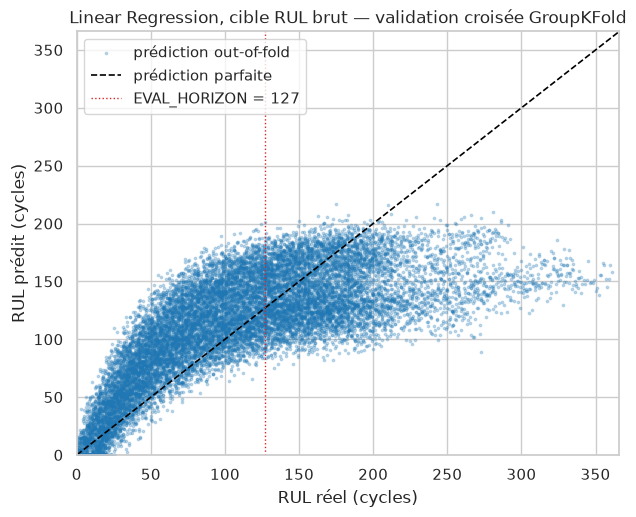

In [15]:
# Prédictions out-of-fold de la Linear Regression sur RUL brut, pour visualiser le comportement.
_, _, _, oof_raw = cross_validate_config(CANDIDATE_FEATURES, model_name="LinearRegression", cap=None)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(y_analysis, oof_raw, s=3, alpha=0.25, color="tab:blue", label="prédiction out-of-fold")
lim = [0, max(y_analysis.max(), oof_raw.max()) + 5]
ax.plot(lim, lim, color="black", lw=1.2, ls="--", label="prédiction parfaite")
ax.axvline(EVAL_HORIZON, color="tab:red", lw=1, ls=":", label=f"EVAL_HORIZON = {EVAL_HORIZON}")
ax.set(xlim=lim, ylim=lim, xlabel="RUL réel (cycles)", ylabel="RUL prédit (cycles)",
       title="Linear Regression, cible RUL brut — validation croisée GroupKFold")
ax.legend(loc="upper left")
save_figure(fig, "01_lr_rul_brut_pred_vs_reel")
plt.show()

**Lecture.** Le modèle linéaire sur RUL brut écrase les grandes valeurs : au-delà d'environ 150 cycles de RUL réel, les prédictions plafonnent naturellement, car les capteurs ne changent presque pas en début de vie. Le modèle essaie pourtant de « tirer » sa droite vers ces valeurs, ce qui dégrade sa précision **près de la panne**, là où elle compte le plus.

C'est exactement le problème que le **RUL plafonné** cherche à résoudre (section 8). Ridge avec `alpha = 1` donne quasiment le même résultat que la Linear Regression : la question de la régularisation est traitée en section 9.

## 8. Cible : RUL brut ou RUL plafonné

**Objectif.** Décider objectivement de la cible d'apprentissage (décision 7 de l'EDA, « à valider »).

> **RUL plafonné (*piecewise-linear RUL*).** On apprend $\min(\text{RUL}, \text{cap})$ au lieu du RUL brut. Idée : tant que le moteur est sain, on ne peut pas savoir s'il lui reste 200 ou 300 cycles ; on lui dit simplement « au moins `cap` ». Le modèle se concentre alors sur la phase de dégradation.

Le plafond est un **hyperparamètre** : il est choisi en validation croisée, parmi les valeurs déclarées en section 1 (`RUL_CAPS`), avec le critère RMSE zone contre le RUL réel. Seule la cible d'**apprentissage** est plafonnée ; l'évaluation utilise toujours le RUL réel.

In [16]:
cap_rows = []
for model_name in ("LinearRegression", "Ridge"):
    for cap in RUL_CAPS:
        mean, std, _, _ = cross_validate_config(CANDIDATE_FEATURES, model_name=model_name, cap=cap)
        cap_rows.append({"modèle": model_name, "cap": "brut" if cap is None else cap,
                         "RMSE_zone": mean["RMSE_zone"], "RMSE_zone_std": std["RMSE_zone"],
                         "MAE_zone": mean["MAE_zone"], "RMSE_global": mean["RMSE_global"]})
cap_results = pd.DataFrame(cap_rows)
cap_results.pivot(index="cap", columns="modèle", values="RMSE_zone").round(3)

modèle,LinearRegression,Ridge
cap,,
80,23.963,23.963
90,21.522,21.522
100,20.314,20.314
110,20.230,20.230
120,21.001,21.001
125,21.605,21.605
130,22.305,22.305
140,23.868,23.868
150,25.484,25.484


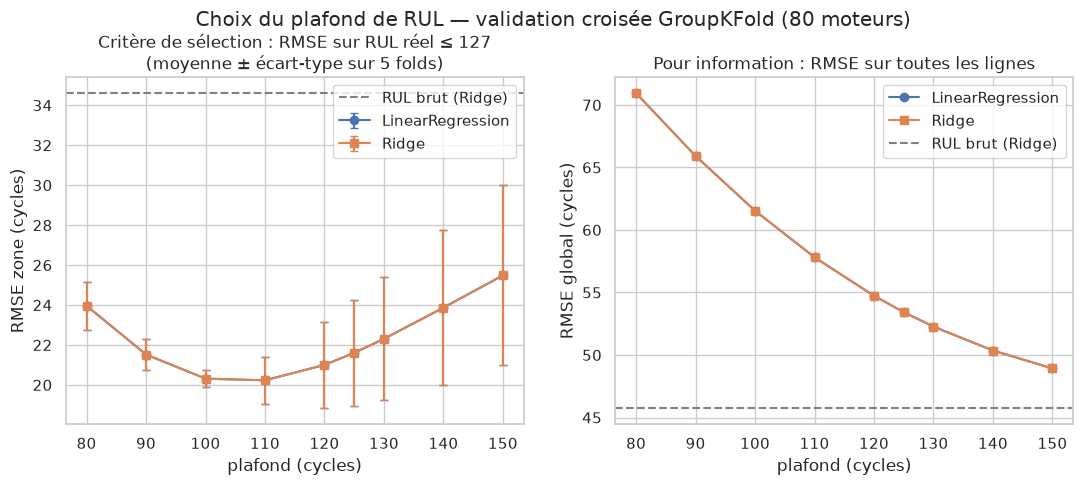

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_name, marker in (("LinearRegression", "o"), ("Ridge", "s")):
    sub = cap_results[(cap_results["modèle"] == model_name) & (cap_results["cap"] != "brut")]
    axes[0].errorbar(sub["cap"].astype(int), sub["RMSE_zone"], yerr=sub["RMSE_zone_std"], marker=marker,
                     capsize=3, label=model_name)
    axes[1].plot(sub["cap"].astype(int), sub["RMSE_global"], marker=marker, label=model_name)
raw_ridge = cap_results[(cap_results["cap"] == "brut") & (cap_results["modèle"] == "Ridge")].iloc[0]
raw_zone, raw_global = raw_ridge["RMSE_zone"], raw_ridge["RMSE_global"]
axes[0].axhline(raw_zone, color="grey", ls="--", label="RUL brut (Ridge)")
axes[1].axhline(raw_global, color="grey", ls="--", label="RUL brut (Ridge)")
axes[0].set(xlabel="plafond (cycles)", ylabel="RMSE zone (cycles)",
            title=f"Critère de sélection : RMSE sur RUL réel ≤ {EVAL_HORIZON}\n(moyenne ± écart-type sur 5 folds)")
axes[1].set(xlabel="plafond (cycles)", ylabel="RMSE global (cycles)",
            title="Pour information : RMSE sur toutes les lignes")
for ax in axes:
    ax.legend()
fig.suptitle("Choix du plafond de RUL — validation croisée GroupKFold (80 moteurs)", y=1.03)
save_figure(fig, "02_choix_plafond_rul")
plt.show()

In [18]:
best_cap_row = cap_results.loc[cap_results["RMSE_zone"].idxmin()]
best_cap_by_model = cap_results.loc[cap_results.groupby("modèle")["RMSE_zone"].idxmin(), ["modèle", "cap", "RMSE_zone"]]
display(best_cap_by_model.set_index("modèle"))
print(f"Plafond retenu provisoirement : {best_cap_row['cap']} (meilleur RMSE zone, {best_cap_row['modèle']})")

,cap,RMSE_zone
modèle,,
LinearRegression,110,20.2302
Ridge,110,20.2302


Plafond retenu provisoirement : 110 (meilleur RMSE zone, LinearRegression)


**Lecture.** Les deux graphiques montrent un **compromis** :

- sur la **zone utile** (RUL réel ≤ 127, critère de sélection), le RUL brut est nettement le plus mauvais et la courbe présente un minimum intérieur : un plafond trop bas empêche de prédire les RUL moyens, un plafond trop haut ramène le problème du RUL brut ;
- sur **toutes les lignes**, le RUL brut est meilleur, mais uniquement parce qu'il « devine » mieux les très grands RUL du début de vie, qui ne sont pas observables dans les capteurs.

Le critère déclaré à l'avance (RMSE zone) tranche en faveur d'un RUL plafonné. Le plafond exact est confirmé conjointement avec `alpha` en section 9.

## 9. Optimisation d'`alpha` pour Ridge

**Objectif.** Choisir l'intensité de la régularisation.

> **Hyperparamètre.** Réglage choisi **avant** l'apprentissage (ici `alpha` et le plafond), par opposition aux **paramètres** (les coefficients $w_j$) appris par le modèle. On le choisit en validation croisée, jamais sur le test.

On explore une **recherche en grille** (*grid search*) : toutes les combinaisons `plafond × alpha` (10 × 15 = 150 configurations, 5 folds chacune) passent par `cross_validate_config`. Une grille logarithmique (0,001 ; 0,003 ; … ; 10 000) est utilisée car l'effet d'`alpha` se joue en ordres de grandeur.

**Départage des ex aequo.** Si plusieurs `alpha` donnent le même RMSE à moins de `ALPHA_TOLERANCE` (0,01 cycle, déclaré en section 1), on retient le **plus grand** : à précision égale, le modèle le plus contraint est le plus prudent. Sans cette règle, le « meilleur » `alpha` pourrait être la plus petite valeur de la grille par simple égalité numérique, ce qui reviendrait à ne pas régulariser du tout.

In [19]:
grid_rows = []
for cap in RUL_CAPS:
    for alpha in RIDGE_ALPHAS:
        mean, std, _, _ = cross_validate_config(CANDIDATE_FEATURES, model_name="Ridge", alpha=alpha, cap=cap)
        grid_rows.append({"cap": "brut" if cap is None else cap, "alpha": alpha,
                          "RMSE_zone": mean["RMSE_zone"], "RMSE_zone_std": std["RMSE_zone"]})
ridge_grid = pd.DataFrame(grid_rows)

# 1) Le plafond est donné par la meilleure combinaison de la grille.
grid_best = ridge_grid.loc[ridge_grid["RMSE_zone"].idxmin()]
BEST_CAP = None if grid_best["cap"] == "brut" else int(grid_best["cap"])
# 2) À ce plafond, plusieurs alpha sont ex aequo à moins de ALPHA_TOLERANCE près : on retient le PLUS
#    régularisé d'entre eux (coefficients plus contraints, même précision). Règle déclarée en section 1.
same_cap = ridge_grid[ridge_grid["cap"] == grid_best["cap"]]
near_best = same_cap[same_cap["RMSE_zone"] <= same_cap["RMSE_zone"].min() + ALPHA_TOLERANCE]
best_ridge = near_best.loc[near_best["alpha"].idxmax()]
BEST_ALPHA = float(best_ridge["alpha"])
print(f"Minimum brut de la grille : cap = {grid_best['cap']}, alpha = {grid_best['alpha']:g}, "
      f"RMSE zone = {grid_best['RMSE_zone']:.4f}")
print(f"Alpha retenu (le plus régularisé à moins de {ALPHA_TOLERANCE} cycle du minimum) : {BEST_ALPHA:g}, "
      f"RMSE zone = {best_ridge['RMSE_zone']:.4f} ± {best_ridge['RMSE_zone_std']:.3f}")

ridge_grid.pivot(index="alpha", columns="cap", values="RMSE_zone").round(2)

Minimum brut de la grille : cap = 110, alpha = 0.001, RMSE zone = 20.2302
Alpha retenu (le plus régularisé à moins de 0.01 cycle du minimum) : 100, RMSE zone = 20.2334 ± 1.177


cap,80,90,100,110,120,125,130,140,150,brut
alpha,,,,,,,,,,
0.0010,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
0.0032,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
0.0100,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
0.0316,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
0.1000,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
0.3162,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
1.0000,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
3.1623,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60
10.0000,23.96,21.52,20.31,20.23,21.00,21.61,22.31,23.87,25.48,34.60


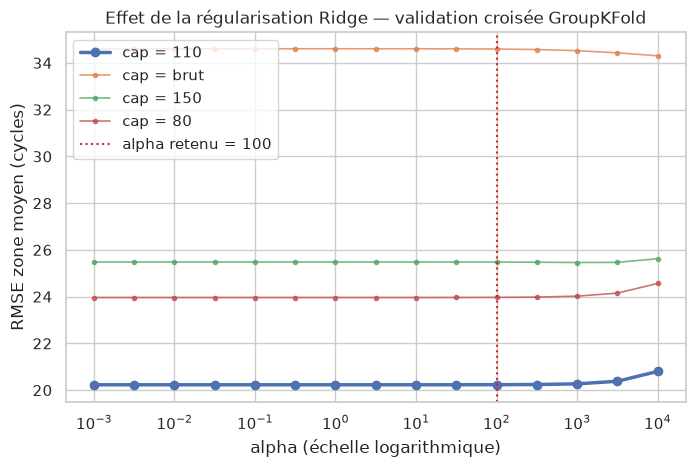

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for cap in (BEST_CAP, None, 150, 80):
    label = "brut" if cap is None else cap
    sub = ridge_grid[ridge_grid["cap"] == label]
    style = dict(lw=2.5, marker="o") if cap == BEST_CAP else dict(lw=1.2, marker=".", alpha=0.8)
    ax.plot(sub["alpha"], sub["RMSE_zone"], label=f"cap = {label}", **style)
ax.axvline(BEST_ALPHA, color="tab:red", ls=":", label=f"alpha retenu = {BEST_ALPHA:g}")
ax.set_xscale("log")
ax.set(xlabel="alpha (échelle logarithmique)", ylabel="RMSE zone moyen (cycles)",
       title="Effet de la régularisation Ridge — validation croisée GroupKFold")
ax.legend()
save_figure(fig, "03_optimisation_alpha_ridge")
plt.show()

In [21]:
# Sensibilité : écart entre le meilleur et le pire alpha, à plafond fixé.
alpha_effect = (ridge_grid[ridge_grid["cap"] == best_ridge["cap"]]
                .assign(ecart_au_meilleur=lambda d: d["RMSE_zone"] - d["RMSE_zone"].min()))
ALPHA_SENSITIVITY_SMALL = alpha_effect.query("alpha <= 100")["ecart_au_meilleur"].max()
print(f"Pour alpha <= 100, le RMSE zone varie de moins de {ALPHA_SENSITIVITY_SMALL:.3f} cycle.")
alpha_effect[["alpha", "RMSE_zone", "ecart_au_meilleur"]].round(4).set_index("alpha").T

Pour alpha <= 100, le RMSE zone varie de moins de 0.003 cycle.


alpha,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.0000,316.2278,1000.0000,3162.2777,10000.0000
RMSE_zone,20.2302,20.2302,20.2302,20.2302,20.2302,20.2302,20.2302,20.2303,20.2305,20.2312,20.2334,20.2412,20.2702,20.3802,20.8012
ecart_au_meilleur,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0003,0.0010,0.0032,0.0110,0.0400,0.1500,0.5710


**Lecture.** Le **plafond** a un effet important sur l'erreur, alors qu'**`alpha` n'a presque aucun effet** tant qu'il reste raisonnable (≤ 100 : variation de quelques millièmes de cycle) ; seules les très fortes valeurs dégradent le modèle en écrasant les coefficients. La règle de départage retient donc la plus forte régularisation encore « gratuite ».

Explication : avec 17 features standardisées et plus de 13 000 lignes d'apprentissage par fold, le problème est déjà bien conditionné. La redondance des capteurs ne rend pas la Linear Regression instable au point de nuire à la prédiction. C'est un **résultat**, pas un échec : la régularisation n'est pas nécessaire ici pour la précision, mais elle reste utile pour stabiliser les coefficients (section 10).

## 10. Comparaison objective des modèles

**Objectif.** Comparer les candidats **sur le même protocole** (mêmes 5 folds, même critère) et décider avec une règle explicite.

> **Règle de décision.** Une différence de RMSE moyen n'est considérée comme réelle que si elle dépasse l'**écart-type inter-folds** de la référence ; sinon, les modèles sont jugés équivalents et l'on retient le plus simple ou le plus robuste.

Pour juger aussi la **robustesse**, on compare la stabilité des coefficients d'un fold à l'autre : un modèle dont les coefficients changent beaucoup selon les moteurs d'apprentissage est plus fragile.

In [22]:
lr_best_cap_label = best_cap_by_model.set_index("modèle").loc["LinearRegression", "cap"]
LR_BEST_CAP = None if lr_best_cap_label == "brut" else int(lr_best_cap_label)

comparison_specs = {
    "LinearRegression — RUL brut": dict(model_name="LinearRegression", cap=None),
    "Ridge (alpha=1) — RUL brut": dict(model_name="Ridge", alpha=DEFAULT_RIDGE_ALPHA, cap=None),
    f"LinearRegression — cap {LR_BEST_CAP}": dict(model_name="LinearRegression", cap=LR_BEST_CAP),
    f"Ridge (alpha={BEST_ALPHA:g}) — cap {BEST_CAP}": dict(model_name="Ridge", alpha=BEST_ALPHA, cap=BEST_CAP),
}
comparison = pd.DataFrame([cv_row(label, CANDIDATE_FEATURES, **spec) for label, spec in comparison_specs.items()])
comparison = comparison.set_index("configuration").sort_values("RMSE_zone")
comparison.round(3)

,n_features,MAE_zone,RMSE_zone,R2_zone,RMSE_global,R2_global,RMSE_zone_std
configuration,,,,,,,
LinearRegression — cap 110,17,16.432,20.230,0.699,57.813,0.310,1.180
Ridge (alpha=100) — cap 110,17,16.438,20.233,0.699,57.826,0.310,1.177
Ridge (alpha=1) — RUL brut,17,27.935,34.604,0.094,45.743,0.568,7.023
LinearRegression — RUL brut,17,27.935,34.604,0.094,45.743,0.568,7.023


In [23]:
def coefficient_stability(model_name, alpha, cap):
    # Coefficients standardisés appris sur chacun des 5 folds -> moyenne et écart-type par feature.
    coefs = []
    y_target = cap_target(y_analysis, cap)
    for train_idx, _ in CV_FOLDS:
        pipe = make_pipeline(make_model(model_name, alpha)).fit(X_analysis.iloc[train_idx], y_target[train_idx])
        coefs.append(pipe.named_steps["regressor"].coef_)
    coefs = pd.DataFrame(coefs, columns=CANDIDATE_FEATURES)
    return coefs.mean(), coefs.std(ddof=1)


lr_mean, lr_std = coefficient_stability("LinearRegression", None, BEST_CAP)
ridge_mean, ridge_std = coefficient_stability("Ridge", BEST_ALPHA, BEST_CAP)
coef_table = pd.DataFrame({"LR coef": lr_mean, "LR std folds": lr_std,
                           "Ridge coef": ridge_mean, "Ridge std folds": ridge_std})
COEF_STD_RATIO = float(ridge_std.mean() / lr_std.mean())
print(f"Variabilité moyenne des coefficients Ridge / LR (même plafond {BEST_CAP}) : {COEF_STD_RATIO:.3f}")
coef_table.round(3).sort_values("Ridge coef")

Variabilité moyenne des coefficients Ridge / LR (même plafond 110) : 0.948


,LR coef,LR std folds,Ridge coef,Ridge std folds
sensor_9,-5.416,0.318,-5.262,0.275
sensor_11,-5.152,0.082,-5.065,0.080
sensor_14,-3.842,0.179,-3.960,0.150
sensor_4,-3.541,0.212,-3.536,0.205
sensor_15,-2.874,0.178,-2.881,0.174
sensor_2,-2.166,0.041,-2.184,0.040
sensor_17,-1.649,0.111,-1.680,0.108
sensor_3,-1.613,0.104,-1.640,0.102
sensor_13,-1.382,0.182,-1.397,0.177
sensor_8,-1.255,0.184,-1.278,0.178


In [24]:
reference_label = comparison.index[0]
reference = comparison.iloc[0]
lr_label = f"LinearRegression — cap {LR_BEST_CAP}"
ridge_label = f"Ridge (alpha={BEST_ALPHA:g}) — cap {BEST_CAP}"
LR_RIDGE_GAP = abs(comparison.loc[lr_label, "RMSE_zone"] - comparison.loc[ridge_label, "RMSE_zone"])
equivalent = LR_RIDGE_GAP < comparison.loc[ridge_label, "RMSE_zone_std"]

# Décision : si LR et Ridge sont équivalents, on retient Ridge (baseline désigné par le README,
# plus robuste à la redondance) ; sinon on retient le meilleur RMSE zone.
SELECTED_MODEL = "Ridge" if equivalent else comparison.loc[[lr_label, ridge_label], "RMSE_zone"].idxmin().split(" ")[0]
SELECTED_ALPHA = BEST_ALPHA if SELECTED_MODEL == "Ridge" else None
SELECTED_CAP = BEST_CAP if SELECTED_MODEL == "Ridge" else LR_BEST_CAP

print(f"Écart LR / Ridge (plafonnés) : {LR_RIDGE_GAP:.4f} cycle -> équivalents : {equivalent}")
print(f"Modèle retenu : {SELECTED_MODEL}, alpha = {SELECTED_ALPHA}, cap = {SELECTED_CAP}")

Écart LR / Ridge (plafonnés) : 0.0032 cycle -> équivalents : True
Modèle retenu : Ridge, alpha = 100.0, cap = 110


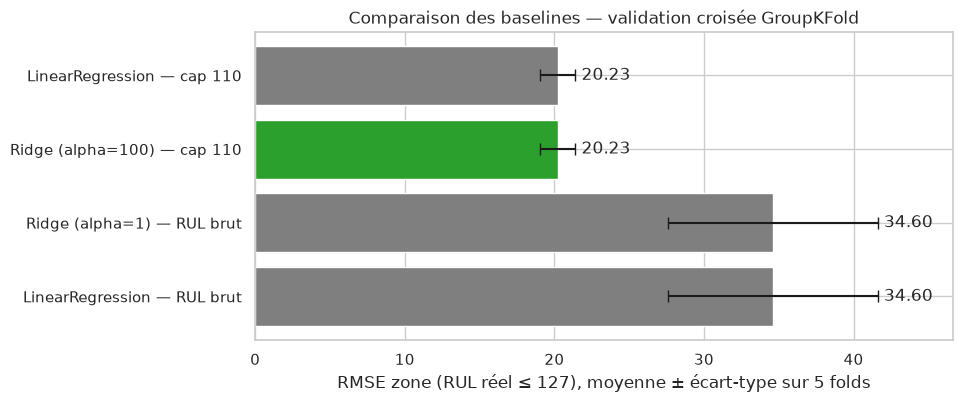

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
order = comparison.sort_values("RMSE_zone", ascending=False)
colors = ["tab:green" if lbl == ridge_label else "tab:gray" for lbl in order.index]
ax.barh(order.index, order["RMSE_zone"], xerr=order["RMSE_zone_std"], color=colors, capsize=4)
for i, (val, std) in enumerate(zip(order["RMSE_zone"], order["RMSE_zone_std"])):
    ax.text(val + std + 0.4, i, f"{val:.2f}", va="center")
ax.set(xlabel=f"RMSE zone (RUL réel ≤ {EVAL_HORIZON}), moyenne ± écart-type sur 5 folds",
       title="Comparaison des baselines — validation croisée GroupKFold")
ax.set_xlim(0, order["RMSE_zone"].max() + order["RMSE_zone_std"].max() + 5)
save_figure(fig, "04_comparaison_modeles_cv")
plt.show()

**Lecture.** Une fois la cible plafonnée, **Linear Regression et Ridge sont équivalents en précision** : leur écart est très inférieur à la variabilité entre folds. Le gain vient presque entièrement du **plafonnement de la cible**, pas du choix entre les deux modèles.

Conformément à la règle de décision, on retient **Ridge** : c'est le baseline désigné par le README, et ses coefficients sont au moins aussi stables d'un fold à l'autre (rapport de variabilité Ridge / LR affiché ci-dessus, ≤ 1), ce qui compte pour l'interprétation et pour la suite du projet. La légère régularisation ne coûte rien en précision et protège contre la redondance des capteurs si la liste de features évolue.

## 11. Ablations demandées par l'EDA

**Objectif.** Tester les décisions laissées « à valider » par l'EDA (README §8.3, décisions 8 à 11 ; §10.2, étapes 3 et 8).

> **Ablation.** Expérience qui retire (ou ajoute) un élément pour mesurer son effet réel. C'est la seule façon de **confirmer** une hypothèse de l'EDA (règle « observation ≠ preuve »).

Toutes les variantes utilisent le modèle et les hyperparamètres retenus en section 10, les mêmes folds et le même critère. La configuration de référence n'est modifiée **que si** une variante améliore le RMSE zone d'au moins un écart-type inter-folds.

**Features causales (moyennes glissantes).** Pour chaque capteur, la moyenne des W derniers cycles **du même moteur** (passé uniquement, `min_periods=1` au début de trajectoire). Elles lissent le bruit de mesure sans utiliser le futur et sans traverser deux trajectoires (règle 5 du README).

In [26]:
CANDIDATE_SENSORS = [f for f in CANDIDATE_FEATURES if f.startswith("sensor_")]


def add_rolling_means(df, window, columns=CANDIDATE_SENSORS):
    # Moyenne glissante CAUSALE par moteur : la valeur au cycle t n'utilise que les cycles <= t.
    out = df.sort_values(ID_COLUMNS).copy()
    rolled = (out.groupby("unit_id")[columns]
                 .rolling(window=window, min_periods=1).mean()      # fenêtre tournée vers le passé
                 .reset_index(level=0, drop=True))                   # réaligne sur l'index d'origine
    new_cols = [f"{c}_rm{window}" for c in columns]
    out[new_cols] = rolled.loc[out.index, columns].to_numpy()   # alignement explicite par index
    return out, new_cols


# Test de causalité : modifier le futur d'un moteur ne doit pas changer ses moyennes passées.
probe = analysis_df[analysis_df["unit_id"] == ANALYSIS_ENGINES[0]].copy()
base, cols = add_rolling_means(probe, 10)
probe.loc[probe["cycle"] > 50, CANDIDATE_SENSORS] += 1_000.0
modified, _ = add_rolling_means(probe, 10)
assert np.allclose(base.loc[base["cycle"] <= 50, cols], modified.loc[modified["cycle"] <= 50, cols])
print("Moyennes glissantes causales : vérifié (aucune information future).")

Moyennes glissantes causales : vérifié (aucune information future).


In [27]:
selected_kwargs = dict(model_name=SELECTED_MODEL, alpha=SELECTED_ALPHA or DEFAULT_RIDGE_ALPHA, cap=SELECTED_CAP)
first_of_group = [group[1:] for group in feature_groups["redundant_groups"]]       # capteurs retirés : 2e de chaque groupe
redundant_dropped = [f for grp in first_of_group for f in grp]

ablations = {
    "Référence (17 features)": CANDIDATE_FEATURES,
    "+ cycle": CANDIDATE_FEATURES + ["cycle"],
    "- sensor_6": [f for f in CANDIDATE_FEATURES if f != "sensor_6"],
    "- setting_1, setting_2": [f for f in CANDIDATE_FEATURES if f not in ("setting_1", "setting_2")],
    "- sensor_6, setting_1, setting_2": [f for f in CANDIDATE_FEATURES if f not in ("sensor_6", "setting_1", "setting_2")],
    "- sensor_9, sensor_14": [f for f in CANDIDATE_FEATURES if f not in feature_groups["heterogeneous_trend"]],
    f"1 capteur par groupe redondant (- {', '.join(redundant_dropped)})": [f for f in CANDIDATE_FEATURES if f not in redundant_dropped],
}
ablation_rows = [cv_row(label, feats, **selected_kwargs) for label, feats in ablations.items()]

for window in ROLLING_WINDOWS:
    rolled_df, rm_cols = add_rolling_means(analysis_df, window)
    ablation_rows.append(cv_row(f"+ moyennes glissantes causales W={window}", CANDIDATE_FEATURES + rm_cols,
                                data=rolled_df, **selected_kwargs))

ablation_results = pd.DataFrame(ablation_rows).set_index("configuration")
ref_rmse = ablation_results.loc["Référence (17 features)", "RMSE_zone"]
ref_std = ablation_results.loc["Référence (17 features)", "RMSE_zone_std"]
ablation_results["gain_vs_ref"] = ref_rmse - ablation_results["RMSE_zone"]          # > 0 : variante meilleure
ablation_results["gain_significatif"] = ablation_results["gain_vs_ref"] > ref_std
ablation_results[["n_features", "RMSE_zone", "RMSE_zone_std", "MAE_zone", "R2_zone", "gain_vs_ref", "gain_significatif"]].round(3)

,n_features,RMSE_zone,RMSE_zone_std,MAE_zone,R2_zone,gain_vs_ref,gain_significatif
configuration,,,,,,,
Référence (17 features),17,20.233,1.177,16.438,0.699,0.000,False
+ cycle,18,20.090,0.889,16.321,0.704,0.144,False
- sensor_6,16,20.250,1.162,16.454,0.699,-0.017,False
"- setting_1, setting_2",15,20.232,1.175,16.436,0.699,0.001,False
"- sensor_6, setting_1, setting_2",14,20.249,1.159,16.452,0.699,-0.016,False
"- sensor_9, sensor_14",15,21.320,1.042,17.273,0.666,-1.087,False
"1 capteur par groupe redondant (- sensor_14, sensor_13, sensor_12)",14,20.372,1.172,16.557,0.695,-0.138,False
+ moyennes glissantes causales W=10,32,20.022,1.385,16.188,0.705,0.211,False
+ moyennes glissantes causales W=30,32,19.377,0.795,15.694,0.725,0.856,False


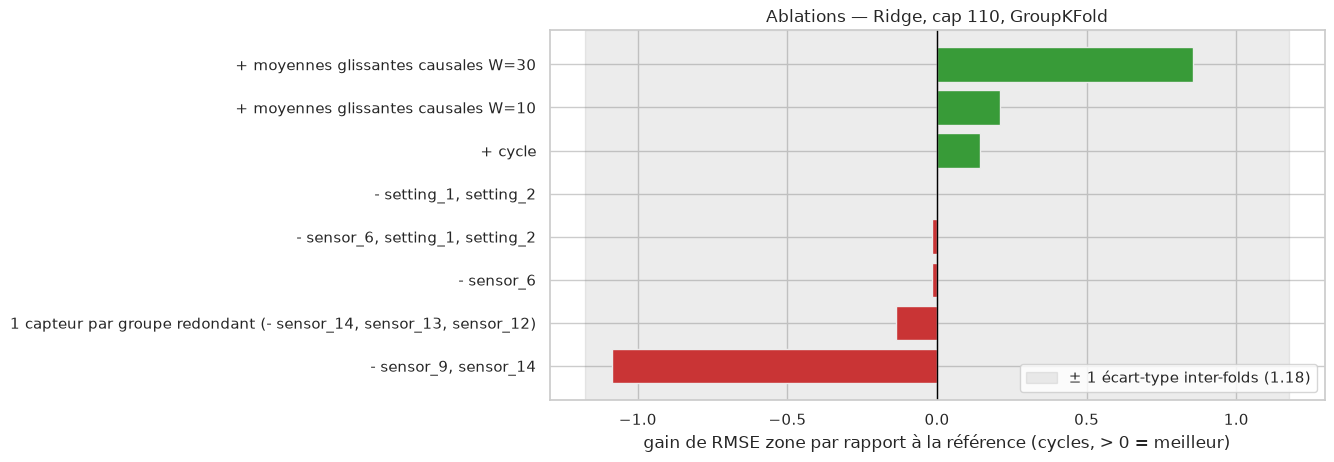

Variantes avec un gain supérieur à 1 écart-type : 0
Features retenues : 17 -> ['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [28]:
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = ablation_results.drop(index="Référence (17 features)").sort_values("gain_vs_ref")
colors = ["tab:green" if g > 0 else "tab:red" for g in plot_df["gain_vs_ref"]]
ax.barh(plot_df.index, plot_df["gain_vs_ref"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.axvspan(-ref_std, ref_std, color="grey", alpha=0.15, label=f"± 1 écart-type inter-folds ({ref_std:.2f})")
ax.set(xlabel="gain de RMSE zone par rapport à la référence (cycles, > 0 = meilleur)",
       title=f"Ablations — {SELECTED_MODEL}, cap {SELECTED_CAP}, GroupKFold")
ax.legend(loc="lower right")
save_figure(fig, "05_ablations")
plt.show()

N_SIGNIFICANT_ABLATIONS = int(ablation_results["gain_significatif"].sum())
SELECTED_FEATURES = CANDIDATE_FEATURES if N_SIGNIFICANT_ABLATIONS == 0 else ablations[ablation_results["gain_vs_ref"].idxmax()]
print(f"Variantes avec un gain supérieur à 1 écart-type : {N_SIGNIFICANT_ABLATIONS}")
print(f"Features retenues : {len(SELECTED_FEATURES)} -> {SELECTED_FEATURES}")

**Lecture.** Aucune variante ne sort de la zone grise (± 1 écart-type inter-folds) : les différences observées sont du même ordre que la variabilité entre groupes de moteurs. La configuration de référence (**17 features**) est donc conservée.

Ce que cela signifie pour chaque décision de l'EDA :

- **`cycle`** : ne change pas significativement la performance. Le garder hors du baseline évite qu'un modèle apprenne « l'âge moyen de la flotte » au lieu de lire l'état du moteur.
- **`sensor_6`, `setting_1`, `setting_2`** : peu informatives mais pas nuisibles pour un modèle linéaire régularisé.
- **`sensor_9`, `sensor_14`** (tendances hétérogènes) : leur retrait est la variante la plus **pénalisante** du tableau. Malgré leur comportement à deux régimes, ils apportent de l'information : on les garde.
- **Redondance** (un capteur par groupe) : légère perte, non significative ; le modèle linéaire absorbe la redondance sans dommage.
- **Moyennes glissantes causales** : léger gain moyen, inférieur au bruit inter-folds. C'est une **piste** à reprendre avec un modèle séquentiel en S4, qui exploite naturellement l'historique.

Ces conclusions valent **pour un modèle linéaire** ; un modèle non linéaire ou séquentiel pourrait en tirer un bénéfice différent.

## 12. Gestion des prédictions RUL négatives

**Objectif.** Un modèle linéaire n'a aucune contrainte de signe : près de la panne, il peut prédire un RUL **négatif**, ce qui n'a pas de sens physique. On mesure l'ampleur du phénomène, puis on applique une règle simple : **ramener à 0 toute prédiction négative** (*clipping*).

Cette règle est un **post-traitement** sans paramètre appris : elle n'utilise aucune donnée et ne peut donc pas créer de fuite. Elle est appliquée identiquement en validation et sur le test. Depuis le début, `cross_validate_config` l'applique par défaut ; ici on désactive le clipping pour en mesurer l'effet.

In [29]:
_, _, _, oof_unclipped = cross_validate_config(SELECTED_FEATURES, clip=False, **selected_kwargs)
oof_clipped = clip_negative(oof_unclipped)

N_NEGATIVE_OOF = int((oof_unclipped < 0).sum())
negative_summary = pd.DataFrame(
    {"sans clipping": evaluate_predictions(y_analysis, oof_unclipped),
     "avec clipping à 0": evaluate_predictions(y_analysis, oof_clipped)}
).T[["MAE_zone", "RMSE_zone", "R2_zone", "RMSE_global"]]

print(f"Prédictions négatives (out-of-fold) : {N_NEGATIVE_OOF} sur {len(oof_unclipped)} "
      f"({N_NEGATIVE_OOF / len(oof_unclipped):.2%}), minimum = {oof_unclipped.min():.2f}")
print(f"RUL réel moyen des lignes concernées : {y_analysis[oof_unclipped < 0].mean():.2f} cycles")
negative_summary.round(4)

Prédictions négatives (out-of-fold) : 305 sur 16561 (1.84%), minimum = -70.64
RUL réel moyen des lignes concernées : 4.74 cycles


,MAE_zone,RMSE_zone,R2_zone,RMSE_global
sans clipping,16.8829,20.6128,0.6888,57.9722
avec clipping à 0,16.4382,20.2608,0.6993,57.8955


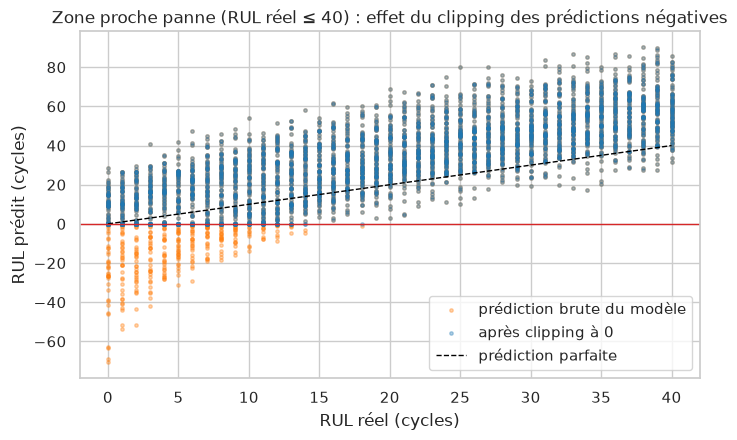

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
near_failure = y_analysis <= 40
ax.scatter(y_analysis[near_failure], oof_unclipped[near_failure], s=6, alpha=0.35, color="tab:orange",
           label="prédiction brute du modèle")
ax.scatter(y_analysis[near_failure], oof_clipped[near_failure], s=6, alpha=0.35, color="tab:blue",
           label="après clipping à 0")
ax.plot([0, 40], [0, 40], color="black", ls="--", lw=1, label="prédiction parfaite")
ax.axhline(0, color="tab:red", lw=1)
ax.set(xlabel="RUL réel (cycles)", ylabel="RUL prédit (cycles)",
       title="Zone proche panne (RUL réel ≤ 40) : effet du clipping des prédictions négatives")
ax.legend()
save_figure(fig, "06_clipping_predictions_negatives")
plt.show()

**Lecture.** Les prédictions négatives sont **rares** et se concentrent sur les tout derniers cycles avant la panne. Le clipping supprime ces valeurs impossibles et ne peut que réduire l'erreur sur ces lignes (le RUL réel y est ≥ 0). L'effet sur les métriques globales est très faible, mais la règle est indispensable pour l'API et le dashboard : un RUL affiché ne doit jamais être négatif.

## 13. Vérification sur les 20 moteurs de validation figés

**Objectif.** Toutes les décisions ont été prises en validation croisée sur les 80 moteurs d'analyse. On vérifie maintenant la configuration retenue sur les **20 moteurs de validation** de l'EDA, jamais utilisés jusqu'ici (README §10.2, étape 5).

Le pipeline est entraîné sur les 80 moteurs d'analyse, puis évalué une seule fois sur les 20 moteurs de validation. Si le score était très différent de la validation croisée, ce serait un signal d'alerte (sur-ajustement des choix, split défavorable…).

In [31]:
def fit_baseline(df, features=None, model_name=None, alpha=None, cap=None):
    # Entraîne le pipeline retenu (scaler + modèle) sur un DataFrame doté du RUL.
    features = SELECTED_FEATURES if features is None else features
    X, y, _ = make_xy(df, features)
    pipe = make_pipeline(make_model(model_name or SELECTED_MODEL, alpha or SELECTED_ALPHA or DEFAULT_RIDGE_ALPHA))
    return pipe.fit(X, cap_target(y, SELECTED_CAP if cap is None else cap))


def predict_rul(pipeline, df, features=None):
    # Prédiction RUL avec la règle de post-traitement (clipping à 0).
    features = SELECTED_FEATURES if features is None else features
    return clip_negative(pipeline.predict(df[features]))


validation_pipeline = fit_baseline(analysis_df)
validation_pred = predict_rul(validation_pipeline, validation_df)

selected_cv_mean, selected_cv_std, selected_cv_folds, selected_oof = cross_validate_config(SELECTED_FEATURES, **selected_kwargs)
validation_metrics = evaluate_predictions(y_validation, validation_pred)

val_vs_cv = pd.DataFrame({
    "validation croisée (80 moteurs, moyenne)": selected_cv_mean,
    "validation croisée (écart-type)": selected_cv_std,
    "validation figée (20 moteurs)": pd.Series(validation_metrics),
}).loc[["MAE_zone", "RMSE_zone", "R2_zone", "MAE_global", "RMSE_global", "R2_global"]]
val_vs_cv.round(3)

,"validation croisée (80 moteurs, moyenne)",validation croisée (écart-type),validation figée (20 moteurs)
MAE_zone,16.438,1.061,15.240
RMSE_zone,20.233,1.177,18.933
R2_zone,0.699,0.035,0.737
MAE_global,40.187,1.603,36.518
RMSE_global,57.826,3.265,51.008
R2_global,0.310,0.060,0.396


In [32]:
# Erreur par moteur de validation (zone RUL <= EVAL_HORIZON).
validation_results = validation_df[["unit_id", "cycle", "RUL"]].assign(RUL_pred=validation_pred)
validation_results["erreur"] = validation_results["RUL_pred"] - validation_results["RUL"]   # > 0 : prédiction tardive
zone_val = validation_results[validation_results["RUL"] <= EVAL_HORIZON]
per_engine = (zone_val.groupby("unit_id")
              .apply(lambda g: pd.Series({"RMSE_zone": np.sqrt((g["erreur"] ** 2).mean()),
                                          "biais_moyen": g["erreur"].mean(),
                                          "longueur_vie": validation_df.loc[validation_df["unit_id"] == g.name, "cycle"].max()}),
                     include_groups=False)
              .sort_values("RMSE_zone"))
per_engine.round(2).T

unit_id,5,54,11,34,71,13,46,78,23,81,32,77,31,19,40,91,1,74,45,84
RMSE_zone,9.53,10.50,12.5,14.64,15.09,15.69,17.01,17.79,18.68,18.97,19.11,19.71,20.04,20.35,22.15,22.36,23.02,23.54,23.65,24.62
biais_moyen,-2.21,0.65,5.6,-4.35,-4.50,-1.00,10.42,13.31,2.76,-4.47,-8.49,5.86,15.08,0.35,-14.61,-3.07,16.50,16.54,18.55,-14.00
longueur_vie,269.00,257.00,240.0,195.00,208.00,163.00,256.00,231.00,168.00,240.00,191.00,154.00,234.00,158.00,188.00,135.00,192.00,166.00,158.00,267.00


In [33]:
def rul_band_table(results, bands=RUL_BANDS):
    # Erreurs par tranche de RUL réel : où le modèle est-il fiable ?
    labels = [f"{int(lo)}–{int(hi)}" if np.isfinite(hi) else f"> {int(lo)}" for lo, hi in zip(bands[:-1], bands[1:])]
    band = pd.cut(results["RUL"], bins=bands, labels=labels, include_lowest=True)
    return (results.assign(tranche=band).groupby("tranche", observed=True)
            .apply(lambda g: pd.Series({"lignes": len(g),
                                        "MAE": g["erreur"].abs().mean(),
                                        "RMSE": np.sqrt((g["erreur"] ** 2).mean()),
                                        "biais_moyen": g["erreur"].mean()}), include_groups=False))


validation_bands = rul_band_table(validation_results)
validation_bands.round(2)

,lignes,MAE,RMSE,biais_moyen
tranche,,,,
0–25,520.0,12.94,15.98,10.94
25–75,1000.0,14.86,17.99,13.42
75–127,1040.0,16.75,21.06,-12.35
> 127,1510.0,72.59,80.03,-72.59


**Lecture.**

- Le score sur les 20 moteurs de validation est **cohérent** avec la validation croisée (à environ un écart-type, légèrement meilleur) : les choix faits en sections 8 à 11 se généralisent à des moteurs jamais vus.
- **Par tranche de RUL** : l'erreur absolue est la plus faible près de la panne et augmente avec le RUL réel.
- **Biais près de la panne** : dans les tranches 0–25 et 25–75, le biais moyen est **positif** : le modèle annonce en moyenne **plus** de vie qu'il n'en reste. C'est la direction **dangereuse** (panne plus tôt que prévu) ; c'est le point faible principal du baseline, à surveiller dans le Health Score (S5).
- **Au-delà de 127**, le biais devient fortement négatif : c'est l'effet **voulu** du plafond (le modèle annonce « environ `cap` » pour un moteur encore sain), donc une erreur prudente et sans conséquence opérationnelle.
- **Par moteur** : l'erreur varie sensiblement d'un moteur à l'autre ; le baseline ne capte pas les différences individuelles de dégradation (usure initiale inconnue, mentionnée dans l'EDA).

## 14. Graphiques : prédictions et erreurs

**Objectif.** Visualiser le comportement du modèle retenu sur les 20 moteurs de validation :

1. prédiction contre réel (nuage de points) ;
2. distribution des erreurs par tranche de RUL ;
3. trajectoires prédites vs réelles pour quelques moteurs (le meilleur, le pire, deux intermédiaires).

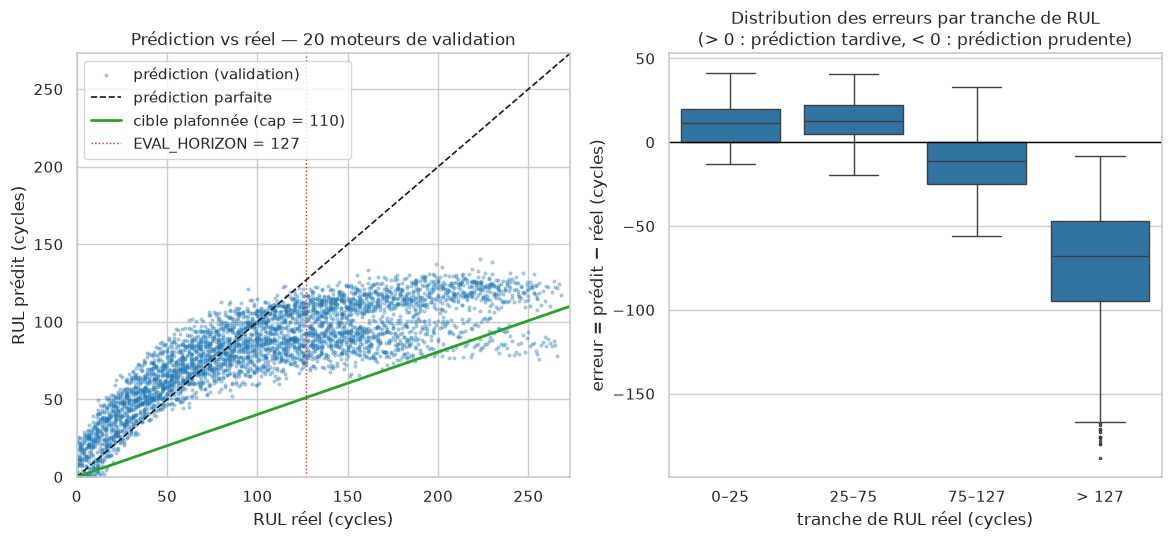

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.scatter(validation_results["RUL"], validation_results["RUL_pred"], s=4, alpha=0.3, color="tab:blue",
           label="prédiction (validation)")
lim = [0, validation_results["RUL"].max() + 5]
ax.plot(lim, lim, "k--", lw=1.2, label="prédiction parfaite")
ax.plot(lim, np.minimum(lim, SELECTED_CAP), color="tab:green", lw=2, label=f"cible plafonnée (cap = {SELECTED_CAP})")
ax.axvline(EVAL_HORIZON, color="tab:red", ls=":", lw=1, label=f"EVAL_HORIZON = {EVAL_HORIZON}")
ax.set(xlim=lim, ylim=[0, lim[1]], xlabel="RUL réel (cycles)", ylabel="RUL prédit (cycles)",
       title="Prédiction vs réel — 20 moteurs de validation")
ax.legend(loc="upper left")

ax = axes[1]
band_labels = validation_bands.index.tolist()
band = pd.cut(validation_results["RUL"], bins=RUL_BANDS, labels=band_labels, include_lowest=True)
sns.boxplot(x=band, y=validation_results["erreur"], ax=ax, color="tab:blue", fliersize=1.5)
ax.axhline(0, color="black", lw=1)
ax.set(xlabel="tranche de RUL réel (cycles)", ylabel="erreur = prédit − réel (cycles)",
       title="Distribution des erreurs par tranche de RUL\n(> 0 : prédiction tardive, < 0 : prédiction prudente)")

save_figure(fig, "07_validation_pred_vs_reel_et_erreurs")
plt.show()

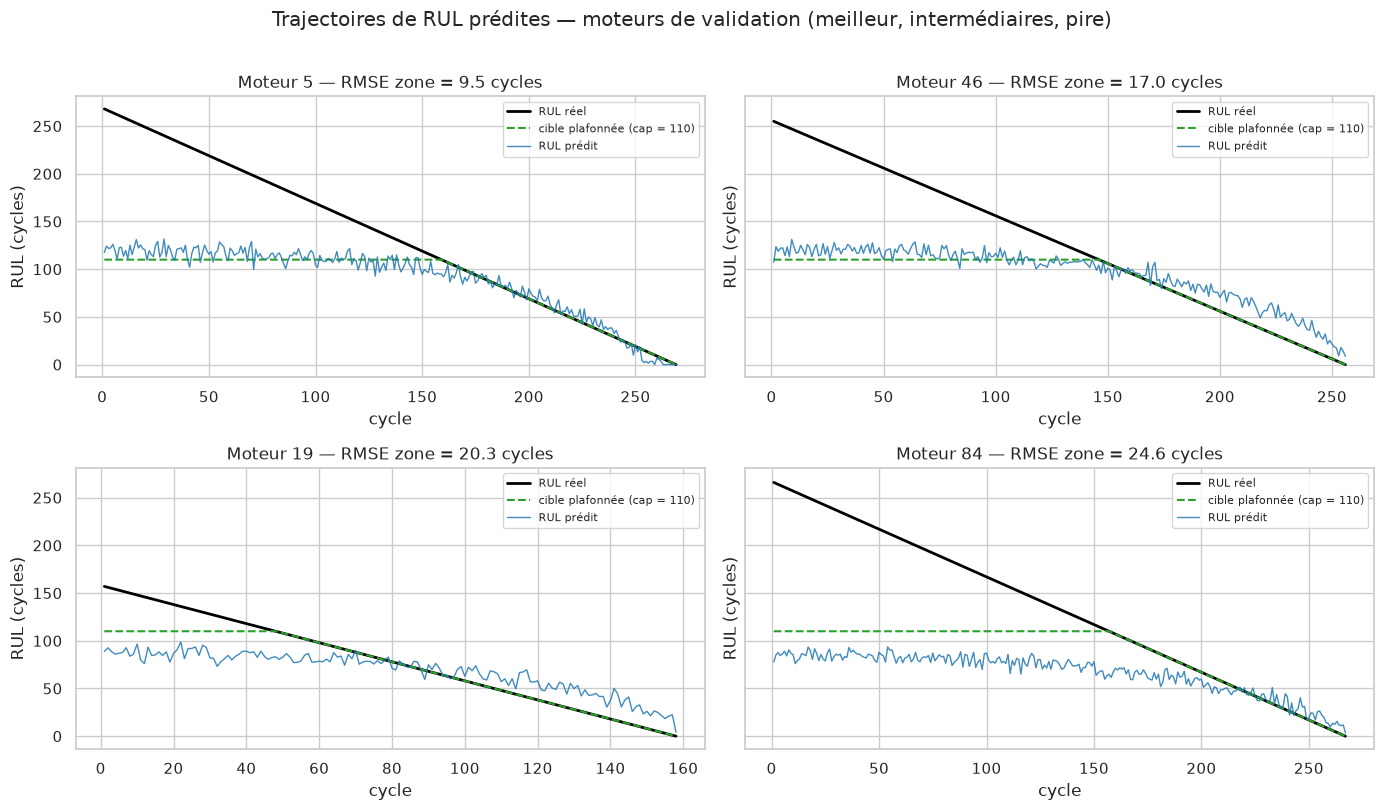

In [35]:
ranked = per_engine.index.tolist()
engines_to_plot = [ranked[0], ranked[len(ranked) // 3], ranked[2 * len(ranked) // 3], ranked[-1]][:N_ENGINES_TO_PLOT]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, unit in zip(axes.ravel(), engines_to_plot):
    eng = validation_results[validation_results["unit_id"] == unit]
    ax.plot(eng["cycle"], eng["RUL"], color="black", lw=2, label="RUL réel")
    ax.plot(eng["cycle"], np.minimum(eng["RUL"], SELECTED_CAP), color="tab:green", ls="--", lw=1.5,
            label=f"cible plafonnée (cap = {SELECTED_CAP})")
    ax.plot(eng["cycle"], eng["RUL_pred"], color="tab:blue", lw=1, alpha=0.85, label="RUL prédit")
    ax.set(title=f"Moteur {unit} — RMSE zone = {per_engine.loc[unit, 'RMSE_zone']:.1f} cycles",
           xlabel="cycle", ylabel="RUL (cycles)")
    ax.legend(fontsize=8)
fig.suptitle("Trajectoires de RUL prédites — moteurs de validation (meilleur, intermédiaires, pire)", y=1.01)
fig.tight_layout()
save_figure(fig, "08_trajectoires_validation")
plt.show()

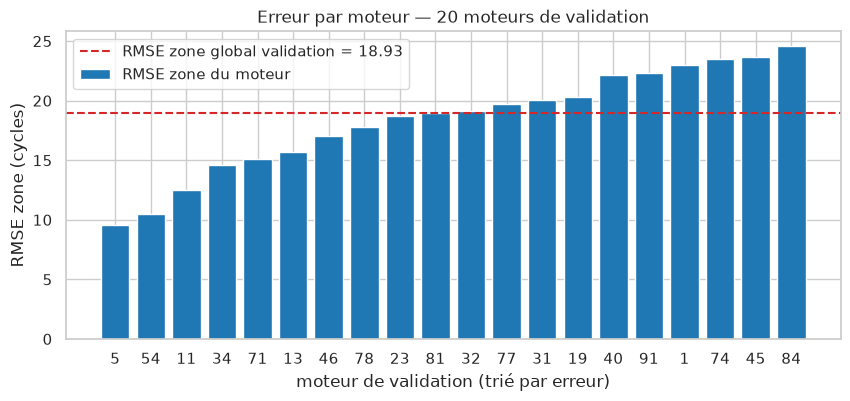

In [36]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_engine.index.astype(str), per_engine["RMSE_zone"], color="tab:blue", label="RMSE zone du moteur")
ax.axhline(validation_metrics["RMSE_zone"], color="tab:red", ls="--",
           label=f"RMSE zone global validation = {validation_metrics['RMSE_zone']:.2f}")
ax.set(xlabel="moteur de validation (trié par erreur)", ylabel="RMSE zone (cycles)",
       title="Erreur par moteur — 20 moteurs de validation")
ax.legend()
save_figure(fig, "09_erreur_par_moteur_validation")
plt.show()

**Lecture.** Les trajectoires prédites suivent bien la **forme** de la cible plafonnée : plateau pendant la phase saine, puis descente vers 0. Elles sont **bruitées** d'un cycle à l'autre, car le modèle ne voit qu'un instant à la fois et les capteurs sont bruités. Ce bruit et les écarts de niveau entre moteurs sont les deux limites principales du baseline, et la motivation directe du modèle séquentiel (S4), qui exploite l'historique de chaque moteur.

## 15. Entraînement final, sauvegarde et rechargement du modèle

**Objectif.** **Figer** le pipeline avant de toucher au test.

Les hyperparamètres (features, plafond, alpha, clipping) sont maintenant figés. Le modèle final est réentraîné sur les **100 moteurs du train** (80 d'analyse + 20 de validation) : utiliser plus de moteurs améliore l'estimation des coefficients, sans rien changer aux choix. C'est la pratique standard : la validation a servi à **choisir**, le réentraînement sert à **exploiter toutes les données étiquetées disponibles**.

> **Sérialisation.** Enregistrer le pipeline entraîné dans un fichier (`joblib`), pour le recharger plus tard (API FastAPI en S6) sans réentraîner. Le pipeline sauvegardé contient le scaler **et** le modèle : impossible de les désynchroniser. Les fichiers `.joblib` sont ignorés par Git (`.gitignore`).

On recharge ensuite le fichier et l'on vérifie qu'il donne **exactement** les mêmes prédictions.

In [37]:
full_train_df = add_rul(train_df)
check_rul(full_train_df)

final_pipeline = fit_baseline(full_train_df)

FINAL_CONFIG = {
    "model": SELECTED_MODEL,
    "alpha": SELECTED_ALPHA,
    "rul_cap": SELECTED_CAP,
    "features": SELECTED_FEATURES,
    "prediction_postprocessing": "clip(prediction, 0, +inf)",
    "trained_on": "100 moteurs de train_FD001 (80 analyse + 20 validation)",
    "selection_criterion": f"RMSE moyen GroupKFold({N_SPLITS}) sur RUL réel <= {EVAL_HORIZON}",
}
PIPELINE_FROZEN = True   # à partir d'ici, plus aucun choix de modélisation n'est autorisé

MODEL_PATH = ARTIFACT_DIR / "ridge_baseline_fd001.joblib"
joblib.dump({"pipeline": final_pipeline, "config": FINAL_CONFIG, "versions": VERSIONS}, MODEL_PATH)
print(f"Modèle sauvegardé : {MODEL_PATH.relative_to(PROJECT_ROOT).as_posix()} ({MODEL_PATH.stat().st_size / 1024:.1f} Ko)")

# Rechargement et contrôle d'identité des prédictions.
bundle = joblib.load(MODEL_PATH)
reloaded_pipeline = bundle["pipeline"]
assert bundle["config"] == FINAL_CONFIG
check_pred_before = predict_rul(final_pipeline, validation_df)
check_pred_after = predict_rul(reloaded_pipeline, validation_df)
assert np.array_equal(check_pred_before, check_pred_after), "le modèle rechargé ne prédit pas la même chose"
print("Modèle rechargé : prédictions strictement identiques.")

pd.Series(final_pipeline.named_steps["regressor"].coef_, index=SELECTED_FEATURES,
          name="coefficient standardisé (modèle final)").sort_values().round(3).to_frame().T

Modèle sauvegardé : artifacts/baseline_fd001/ridge_baseline_fd001.joblib (2.5 Ko)
Modèle rechargé : prédictions strictement identiques.


,sensor_9,sensor_11,sensor_14,sensor_4,sensor_15,sensor_2,sensor_17,sensor_3,sensor_13,sensor_8,setting_1,setting_2,sensor_6,sensor_21,sensor_20,sensor_7,sensor_12
coefficient standardisé (modèle final),-5.38,-5.048,-3.985,-3.458,-2.956,-2.064,-1.695,-1.558,-1.455,-1.309,-0.031,0.031,1.135,2.054,2.117,3.534,4.599


**Lecture des coefficients.** Comme les features sont standardisées, chaque coefficient indique de combien de cycles le RUL prédit varie quand la feature augmente d'un écart-type, **à autres features constantes**. Un coefficient négatif signifie : « quand ce capteur monte, il reste moins de vie ». Attention : avec des capteurs redondants, le poids est **partagé** entre eux ; un coefficient individuel ne doit pas être interprété comme une causalité physique.

## 16. Évaluation finale sur le test NASA FD001

**Objectif.** Mesurer la performance réelle du pipeline figé, selon le protocole du README (§10.2, étape 9).

**Protocole :**

1. Charger `test_FD001.txt` (100 moteurs, trajectoires interrompues avant la panne) et vérifier son empreinte.
2. Pour chaque moteur, ne garder que le **dernier cycle observé** : c'est le moment où l'on veut connaître le RUL.
3. Prédire avec le modèle **rechargé** depuis le disque.
4. Lire `RUL_FD001.txt` (**seule lecture du notebook**) et comparer les 100 prédictions aux 100 valeurs réelles.

Les métriques sont calculées contre le RUL réel **non modifié**. Aucun réglage n'est fait après cette section : quel que soit le résultat, il est rapporté tel quel.

In [38]:
assert PIPELINE_FROZEN, "le pipeline doit être figé avant toute lecture de la vérité terrain du test"

test_df = load_cmapss(TEST_PATH)
assert RAW_SHA256["test_FD001.txt"] == eda_summary["raw_files_sha256"]["test_FD001.txt"]
assert len(test_df) == eda_summary["test"]["n_rows"] and test_df["unit_id"].nunique() == 100

# Dernier cycle observé de chaque moteur de test (une ligne par moteur, ordre unit_id 1 -> 100).
test_last = test_df.loc[test_df.groupby("unit_id")["cycle"].idxmax()].sort_values("unit_id").reset_index(drop=True)
assert test_last["unit_id"].tolist() == list(range(1, 101))
test_pred = predict_rul(reloaded_pipeline, test_last)

# --- SEULE lecture de RUL_FD001.txt dans tout le notebook ----------------------------------
rul_test_true = pd.read_csv(RUL_TEST_PATH, sep=r"\s+", header=None, names=["RUL_true"])["RUL_true"].to_numpy()
RUL_TEST_SHA256 = file_sha256(RUL_TEST_PATH)
assert rul_test_true.shape == (100,) and (rul_test_true >= 0).all()

test_results = test_last[["unit_id", "cycle"]].rename(columns={"cycle": "dernier_cycle_observe"})
test_results["RUL_true"] = rul_test_true          # ligne k de RUL_FD001.txt = moteur k (documentation NASA)
test_results["RUL_pred"] = test_pred
test_results["erreur"] = test_results["RUL_pred"] - test_results["RUL_true"]

test_metrics = regression_metrics(rul_test_true, test_pred, with_nasa=True)
TEST_N_LATE = int((test_results["erreur"] > 0).sum())
pd.Series(test_metrics, name="test FD001 (100 moteurs, dernier cycle)").round(3).to_frame().T

,MAE,RMSE,R2,NASA_score
"test FD001 (100 moteurs, dernier cycle)",18.696,22.687,0.702,1047.1


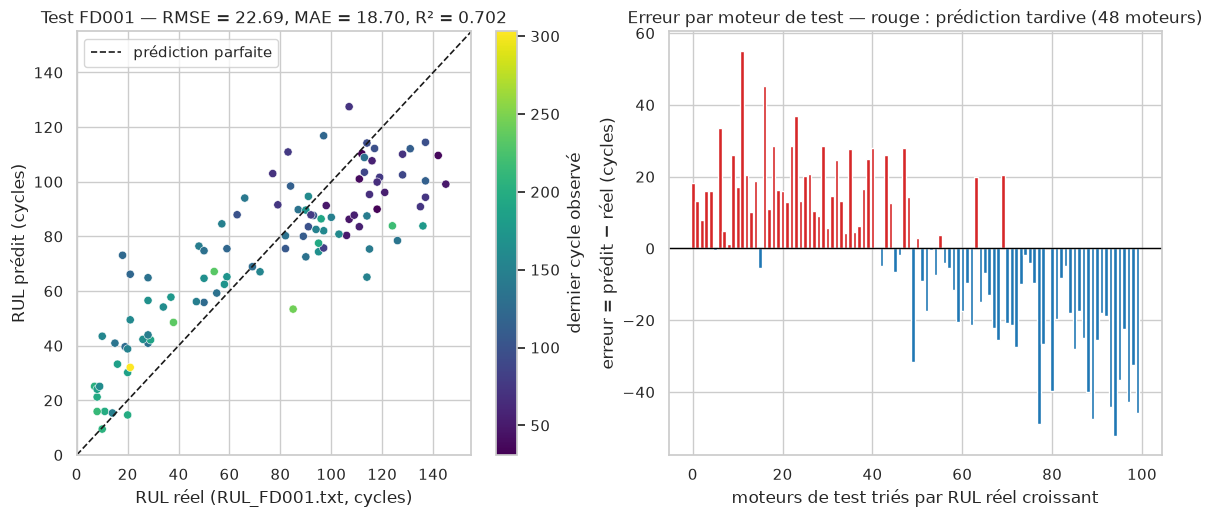

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
sc = ax.scatter(test_results["RUL_true"], test_results["RUL_pred"], c=test_results["dernier_cycle_observe"],
                cmap="viridis", s=35, edgecolor="white", linewidth=0.4)
lim = [0, max(test_results["RUL_true"].max(), test_results["RUL_pred"].max()) + 10]
ax.plot(lim, lim, "k--", lw=1.2, label="prédiction parfaite")
ax.set(xlim=lim, ylim=lim, xlabel="RUL réel (RUL_FD001.txt, cycles)", ylabel="RUL prédit (cycles)",
       title=f"Test FD001 — RMSE = {test_metrics['RMSE']:.2f}, MAE = {test_metrics['MAE']:.2f}, R² = {test_metrics['R2']:.3f}")
fig.colorbar(sc, ax=ax, label="dernier cycle observé")
ax.legend(loc="upper left")

ax = axes[1]
ordered = test_results.sort_values("RUL_true")
ax.bar(range(len(ordered)), ordered["erreur"],
       color=np.where(ordered["erreur"] > 0, "tab:red", "tab:blue"))
ax.axhline(0, color="black", lw=1)
ax.set(xlabel="moteurs de test triés par RUL réel croissant", ylabel="erreur = prédit − réel (cycles)",
       title=f"Erreur par moteur de test — rouge : prédiction tardive ({TEST_N_LATE} moteurs)")
save_figure(fig, "10_test_pred_vs_reel_et_erreurs")
plt.show()

In [40]:
test_band_input = test_results.rename(columns={"RUL_true": "RUL"})
test_bands = rul_band_table(test_band_input, bands=(0, 25, 75, 127, np.inf))

short_history = test_results["dernier_cycle_observe"] < 50
test_history_split = pd.DataFrame({
    "moteurs": [int(short_history.sum()), int((~short_history).sum())],
    "MAE": [test_results.loc[short_history, "erreur"].abs().mean(), test_results.loc[~short_history, "erreur"].abs().mean()],
}, index=["historique < 50 cycles", "historique ≥ 50 cycles"])
display(test_bands.round(2))
test_history_split.round(2)

,lignes,MAE,RMSE,biais_moyen
tranche,,,,
0–25,19.0,18.40,23.08,17.78
25–75,24.0,16.17,18.76,15.75
75–127,47.0,16.87,20.67,-11.43
> 127,10.0,33.88,35.82,-33.88


,moteurs,MAE
historique < 50 cycles,7,20.78
historique ≥ 50 cycles,93,18.54


**Lecture.** Le résultat sur le test officiel est **cohérent** avec la zone utile de la validation : au dernier cycle observé, les RUL réels du test se situent pour l'essentiel dans la zone où le modèle a été optimisé. On retrouve les deux comportements vus en validation :

- **RUL réel élevé (> 127)** : erreur la plus forte, biais négatif — effet attendu du plafond (prédiction prudente) ;
- **proche panne (0–75)** : biais **positif**, donc des prédictions tardives. Ce sont elles qui pèsent le plus dans le score NASA, qui pénalise exponentiellement ce type d'erreur.

Les 7 moteurs à historique court (< 50 cycles) ont une erreur moyenne un peu plus élevée, mais l'effectif est trop faible pour conclure.

Ces chiffres sont **définitifs pour ce baseline** : aucun réglage n'a été ni ne sera fait à partir d'eux.

## 17. Sauvegarde des métriques et artefacts

**Objectif.** Livrer la *Definition of Done* de S3 : `baseline_metrics.json` et les tableaux de résultats, dans `artifacts/baseline_fd001/`. Ce fichier sera la **référence chiffrée** du modèle LSTM / GRU en S4.

| Fichier | Contenu |
|---|---|
| `baseline_metrics.json` | Configuration figée, résultats CV, validation, test, traçabilité (versions, SHA-256) |
| `ridge_baseline_fd001.joblib` | Pipeline final (scaler + Ridge) — non versionné (`.gitignore`) |
| `cv_model_comparison.csv`, `cv_rul_cap_search.csv`, `cv_ridge_alpha_grid.csv`, `cv_ablations.csv` | Tous les résultats de validation croisée |
| `validation_predictions.csv`, `test_predictions.csv` | Prédictions ligne à ligne (pour l'analyse d'erreur et le dashboard) |

In [41]:
def to_builtin(obj):
    # Convertit récursivement les types NumPy / pandas en types Python sérialisables en JSON.
    if isinstance(obj, dict):
        return {str(k): to_builtin(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_builtin(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        return None if not np.isfinite(obj) else round(float(obj), 4)
    return obj


baseline_metrics = {
    "dataset": "FD001",
    "notebook": "02_baseline_fd001.ipynb",
    "final_config": FINAL_CONFIG,
    "evaluation_horizon": EVAL_HORIZON,
    "cross_validation": {
        "method": f"GroupKFold(n_splits={N_SPLITS}) par unit_id sur les 80 moteurs d'analyse",
        "selected_mean": selected_cv_mean.to_dict(),
        "selected_std": selected_cv_std.to_dict(),
        "model_comparison": comparison.to_dict(orient="index"),
        "n_significant_ablations": N_SIGNIFICANT_ABLATIONS,
        "negative_predictions_before_clipping": N_NEGATIVE_OOF,
    },
    "validation_20_engines": {
        "engines": VALIDATION_ENGINES,
        "trained_on": "80 moteurs d'analyse",
        "metrics": validation_metrics,
        "by_rul_band": validation_bands.to_dict(orient="index"),
    },
    "test_fd001": {
        "protocol": "prédiction au dernier cycle observé de chaque moteur, comparée à RUL_FD001.txt (lu une seule fois)",
        "n_engines": int(len(test_results)),
        "metrics": test_metrics,
        "n_late_predictions": TEST_N_LATE,
    },
    "traceability": {
        "raw_files_sha256": {**RAW_SHA256, "RUL_FD001.txt": RUL_TEST_SHA256},
        "eda_split_file": "artifacts/eda_fd001/fd001_engine_split.json",
        "versions": VERSIONS,
        "random_state": RANDOM_STATE,
    },
}

if SAVE_ARTIFACTS:
    (ARTIFACT_DIR / "baseline_metrics.json").write_text(
        json.dumps(to_builtin(baseline_metrics), indent=2, ensure_ascii=False), encoding="utf-8")
    comparison.to_csv(ARTIFACT_DIR / "cv_model_comparison.csv")
    cap_results.to_csv(ARTIFACT_DIR / "cv_rul_cap_search.csv", index=False)
    ridge_grid.to_csv(ARTIFACT_DIR / "cv_ridge_alpha_grid.csv", index=False)
    ablation_results.to_csv(ARTIFACT_DIR / "cv_ablations.csv")
    validation_results.to_csv(ARTIFACT_DIR / "validation_predictions.csv", index=False)
    test_results.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)

# Relecture du JSON pour vérifier qu'il est valide et complet.
reloaded_metrics = json.loads((ARTIFACT_DIR / "baseline_metrics.json").read_text(encoding="utf-8"))
assert reloaded_metrics["test_fd001"]["metrics"]["RMSE"] == round(test_metrics["RMSE"], 4)

pd.DataFrame(
    [(p.parent.relative_to(PROJECT_ROOT).as_posix(), p.name, f"{p.stat().st_size / 1024:.1f} Ko")
     for d in (ARTIFACT_DIR, FIGURE_DIR) for p in sorted(d.iterdir())],
    columns=["dossier", "fichier", "taille"],
)

,dossier,fichier,taille
0,artifacts/baseline_fd001,baseline_metrics.json,4.3 Ko
1,artifacts/baseline_fd001,cv_ablations.csv,1.6 Ko
2,artifacts/baseline_fd001,cv_model_comparison.csv,0.7 Ko
3,artifacts/baseline_fd001,cv_ridge_alpha_grid.csv,7.2 Ko
4,artifacts/baseline_fd001,cv_rul_cap_search.csv,1.8 Ko
5,artifacts/baseline_fd001,ridge_baseline_fd001.joblib,2.5 Ko
6,artifacts/baseline_fd001,ridge_pipeline.joblib,1.9 Ko
7,artifacts/baseline_fd001,test_predictions.csv,4.6 Ko
8,artifacts/baseline_fd001,validation_predictions.csv,185.4 Ko
9,reports/figures/baseline_fd001,01_lr_rul_brut_pred_vs_reel.png,294.4 Ko


## 18. Conclusion

### Résultats obtenus (valeurs réelles de cette exécution)

| Étape | Résultat |
|---|---|
| Configuration retenue | **Ridge (`alpha` = 100), cible RUL plafonnée à 110 cycles, 17 features**, clipping des prédictions négatives à 0 |
| Validation croisée GroupKFold (80 moteurs, RUL réel ≤ 127) | RMSE = **20,23 ± 1,18** · MAE = 16,44 · R² = 0,699 |
| Même modèle sur RUL brut | RMSE zone = 34,60 : le plafonnement réduit l'erreur utile d'environ 42 % |
| Vérification sur les 20 moteurs de validation figés | RMSE zone = **18,93** · MAE zone = 15,24 · R² zone = 0,737 |
| **Test officiel NASA FD001** (100 moteurs, dernier cycle observé) | **RMSE = 22,69 · MAE = 18,70 · R² = 0,702 · score NASA = 1 047,1** |

### Réponses aux questions de départ

- **Q1 — Performance d'un modèle linéaire.** Sur RUL brut, le modèle linéaire explique mal la zone utile (R² zone ≈ 0,09) : il essaie de prédire les très grands RUL du début de vie, qui ne sont pas visibles dans les capteurs.
- **Q2 — Cible.** Le **RUL plafonné** est nettement meilleur sur la zone utile. Le plafond optimal en validation croisée est **110 cycles** (courbe en U entre 80 et 150).
- **Q3 — Régularisation.** `alpha` n'a quasiment aucun effet jusqu'à 100 (variation < 0,003 cycle) : le problème est déjà bien conditionné. `alpha` = 100 est retenu par la règle de départage déclarée (le plus régularisé parmi les ex aequo).
- **Q4 — Linear Regression ou Ridge.** Équivalents (écart de 0,003 cycle, très inférieur à l'écart-type inter-folds). Ridge est retenu : baseline désigné par le README, coefficients légèrement plus stables.
- **Q5 — Ablations de l'EDA.** Aucune variante n'améliore le RMSE de plus d'un écart-type : les 17 features sont conservées. Retirer `sensor_9` et `sensor_14` est la variante la plus pénalisante. Les moyennes glissantes causales (W = 30) donnent le meilleur gain moyen (0,86 cycle), insuffisant pour être jugé significatif.
- **Q6 — Erreurs.** Près de la panne, le modèle est le plus précis mais **biaisé vers des prédictions tardives** (biais moyen de +10,9 cycles pour RUL réel ≤ 25 en validation). Pour les moteurs encore sains, le plafond produit des prédictions volontairement prudentes. 305 prédictions out-of-fold négatives (1,84 %) sont ramenées à 0.
- **Q7 — Test.** RMSE de 22,69 cycles au dernier cycle observé, cohérent avec la validation ; **48 moteurs sur 100** reçoivent une prédiction tardive.

### Limites du baseline

1. **Pas de mémoire temporelle** : le modèle lit un seul cycle à la fois. Ses prédictions sont bruitées d'un cycle à l'autre et il ne peut pas estimer la vitesse de dégradation.
2. **Modèle linéaire** : la dégradation est lente puis accélérée (EDA) ; une droite ne peut pas représenter cette courbure.
3. **Différences entre moteurs** : l'usure initiale de chaque moteur est inconnue ; le baseline n'a aucune référence « début de vie » propre au moteur.
4. **Biais tardif près de la panne** : c'est l'erreur la plus coûteuse en maintenance ; elle devra être prise en compte dans le Health Score et les seuils d'alerte (S5).
5. **Validation limitée** : 20 moteurs de validation, aucun de plus de 269 cycles ; un seul sous-ensemble (FD001) de données **simulées**.
6. **Plafond = choix de modélisation** : au-delà de 110 cycles, le modèle ne distingue pas un moteur neuf d'un moteur à mi-vie. C'est acceptable pour l'alerte, pas pour la planification à long terme.

### Suite du projet

- **S4 — LSTM / GRU** : fenêtres W ∈ {20, 30} par moteur, même split, même critère (RMSE zone, GroupKFold) et même protocole de test. Référence à battre : **RMSE test = 22,69** (`baseline_metrics.json`).
- **Pistes baseline** : moyennes glissantes et pentes causales, Random Forest / Gradient Boosting (README §10.2).
- **Industrialisation** : déplacer `add_rul`, `make_xy`, `add_rolling_means`, `cross_validate_config` et `predict_rul` dans `ml/src/` (`data.py`, `features.py`, `train_baseline.py`, `evaluate.py`), comme demandé par le cahier des charges.

## 19. Vérification automatique des chiffres cités

**Objectif.** Appliquer la règle 6 du README : chaque chiffre de la conclusion provient d'une exécution réelle. Cette cellule recalcule les valeurs citées et échoue si l'une d'elles ne correspond plus (par exemple après une modification du code ou des données).

In [42]:
# Chaque valeur citée dans la conclusion est recalculée à partir des objets du notebook.
# Si une assertion échoue, la conclusion ne correspond plus à l'exécution : il faut la mettre à jour.
def close(value, expected, ndigits):
    return round(float(value), ndigits) == expected

checks = {
    "modèle retenu = Ridge": SELECTED_MODEL == "Ridge",
    "alpha retenu = 100": SELECTED_ALPHA == 100.0,
    "plafond retenu = 110": SELECTED_CAP == 110,
    "17 features": len(SELECTED_FEATURES) == 17,
    "CV RMSE zone = 20,23": close(selected_cv_mean["RMSE_zone"], 20.23, 2),
    "CV écart-type = 1,18": close(selected_cv_std["RMSE_zone"], 1.18, 2),
    "CV MAE zone = 16,44": close(selected_cv_mean["MAE_zone"], 16.44, 2),
    "CV R² zone = 0,699": close(selected_cv_mean["R2_zone"], 0.699, 3),
    "RUL brut RMSE zone = 34,60": close(raw_zone, 34.60, 2),
    "réduction ≈ 42 %": close(1 - selected_cv_mean["RMSE_zone"] / raw_zone, 0.42, 2),
    "R² zone RUL brut ≈ 0,09": close(first_results.loc["LinearRegression — RUL brut", "R2_zone"], 0.09, 2),
    "écart LR / Ridge = 0,003": close(LR_RIDGE_GAP, 0.003, 3),
    "alpha <= 100 : variation < 0,003": ALPHA_SENSITIVITY_SMALL < 0.003 + 5e-4,
    "aucune ablation significative": N_SIGNIFICANT_ABLATIONS == 0,
    "gain W=30 = 0,86": close(ablation_results.loc["+ moyennes glissantes causales W=30", "gain_vs_ref"], 0.86, 2),
    "retrait sensor_9/14 = pire variante": ablation_results["gain_vs_ref"].idxmin() == "- sensor_9, sensor_14",
    "biais RUL ≤ 25 = +10,9": close(validation_bands.iloc[0]["biais_moyen"], 10.9, 1),
    "305 prédictions négatives": N_NEGATIVE_OOF == 305,
    "1,84 % négatives": close(N_NEGATIVE_OOF / len(oof_unclipped), 0.0184, 4),
    "validation RMSE zone = 18,93": close(validation_metrics["RMSE_zone"], 18.93, 2),
    "validation MAE zone = 15,24": close(validation_metrics["MAE_zone"], 15.24, 2),
    "validation R² zone = 0,737": close(validation_metrics["R2_zone"], 0.737, 3),
    "test RMSE = 22,69": close(test_metrics["RMSE"], 22.69, 2),
    "test MAE = 18,70": close(test_metrics["MAE"], 18.70, 2),
    "test R² = 0,702": close(test_metrics["R2"], 0.702, 3),
    "test score NASA = 1 047,1": close(test_metrics["NASA_score"], 1047.1, 1),
    "48 prédictions tardives": TEST_N_LATE == 48,
}
report = pd.Series(checks, name="vérifié")
failed = report[~report].index.tolist()
assert not failed, f"Chiffres de la conclusion à mettre à jour : {failed}"
print(f"{len(report)} chiffres cités vérifiés automatiquement : tous conformes à l'exécution.")

27 chiffres cités vérifiés automatiquement : tous conformes à l'exécution.
